# 🧹 Data Preparation & Preprocessing Pipeline — v3.0
### Dataset: Status Gizi Balita — Kabupaten Jeneponto (2021–2024)

---

| Keterangan | Detail |
|---|---|
| **Nama Mahasiswa** | Sherlly Briliant Saputri |
| **NIM** | 5230411156 |
| **Program Studi** | Informatika |
| **Universitas** | Universitas Teknologi Yogyakarta |
| **Versi** | v3.0 — Final Optimized |
| **Tahun Akademik** | 2025/2026 |

---

**Deskripsi Dataset:**  
Dataset berisi rekaman antropometri **40.071 balita** (0–59 bulan) dari Kabupaten Jeneponto, Sulawesi Selatan.  
Sumber: Mendeley Data — *"Dataset Stunting and Nutritional Status of Toddler from Jeneponto Regency"* (DOI: 10.17632/wzwpc9j5bx.4)

**Fitur Input — 4 atribut antropometri:**
- **Gender** — Jenis kelamin (0 = Perempuan, 1 = Laki-laki)
- **Age (Month)** — Umur dalam bulan (0–59)
- **Weight** — Berat badan (kg)
- **Height** — Tinggi badan (cm)

> ⚠️ **Z-Score BUKAN fitur input** — Z-Score W/A, H/A, W/H secara langsung menentukan label target. Memasukkannya ke model = **data leakage**.

**Target Output — Multi-Output Classification (3 label serentak):**
- **Weight for Age (BB/U)** — Status gizi berat badan menurut umur
- **Height for Age (TB/U)** — Status stunting tinggi badan menurut umur
- **Weight for Height (BB/TB)** — Status gizi berat badan menurut tinggi badan

---

## 📋 Pipeline v3.0

| # | Tahap | Keterangan |
|---|---|---|
| 1 | **Import Library** | Termasuk `joblib` (pengganti pickle) |
| 2 | **Load Dataset** | FILE_PATH, ENCODING_MAP, definisi fitur & target |
| 3 | **Data Understanding & Quality Check** | Laporan kualitas komprehensif |
| 4 | **Data Cleaning** | 6 sub-tahap cleaning |
| 5 | **Data Visualization / EDA** | 5 grafik eksplorasi |
| 6 | **Feature Preparation** | Pisahkan X (unscaled) dan y |
| 7 | **Split Dataset** | **Training 60% / Testing 30% / Validation 10%** |
| 8 | **Verifikasi Split** | Chi-square test + distribusi kelas |
| 9 | **StandardScaler** | Fit dari X_train SAJA → transform semua split |
| 10 | **Feature Importance** | RandomForest untuk validasi fitur |
| 11 | **SMOTE-NC** | Oversampling HANYA pada training set |
| 12 | **Simpan Dataset** | `train_smote.csv`, `test.csv`, `validation.csv`, `scaler.joblib` |
| 13 | **Ringkasan Pipeline** | Statistik lengkap seluruh proses |

---

> 🔧 **Perubahan dari v2.0 → v3.0:**
> 1. **Split 60/30/10**: Training 60%, Testing 30%, Validation 10% (konsisten dengan proposal)
> 2. **Validation set murni**: hanya untuk pengujian akhir pasca-deployment, TIDAK ikut training maupun evaluasi model
> 3. **`joblib` menggantikan `pickle`**: sesuai rekomendasi resmi scikit-learn
> 4. **Chi-square test**: verifikasi kuantitatif distribusi kelas antar split
> 5. **Feature Importance analysis**: validasi kontribusi setiap fitur sebelum modeling
> 6. **Visualisasi distribusi fitur setelah SMOTE**: memverifikasi data sintetis tidak mendistorsi distribusi

## 📦 1. Import Library

In [1]:
# ─── Standard Library ───────────────────────────────────────────────────────
import warnings
import logging
import os
import time
from datetime import datetime

# ─── Data Manipulation ──────────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ─── Visualization ──────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# ─── Machine Learning ───────────────────────────────────────────────────────
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from scipy.stats import chi2_contingency

# ─── Serialisasi (joblib — rekomendasi resmi scikit-learn) ──────────────────
import joblib
# [v3.0] joblib menggantikan pickle:
# - Dioptimalkan untuk objek sklearn (array numpy)
# - Load/save lebih cepat untuk objek besar
# - Format lebih stabil lintas versi

# ─── Configuration ──────────────────────────────────────────────────────────
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_rows', 20)

# ─── Plot Style ─────────────────────────────────────────────────────────────
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
COLORS = {
    'primary'   : '#2196F3',
    'secondary' : '#FF5722',
    'accent'    : '#4CAF50',
    'warning'   : '#FF9800',
    'purple'    : '#9C27B0',
    'teal'      : '#009688'
}

# ─── Logging ────────────────────────────────────────────────────────────────
logging.basicConfig(
    level=logging.INFO,
    format='[%(asctime)s] %(levelname)s — %(message)s',
    datefmt='%H:%M:%S'
)
logger = logging.getLogger('DataPipeline_v3')

logger.info('✅ Semua library berhasil diimport')
print('✅ Library berhasil diimport!')
print(f'   pandas  : {pd.__version__}')
print(f'   numpy   : {np.__version__}')
print(f'   seaborn : {sns.__version__}')
print(f'   joblib  : {joblib.__version__}  [v3.0: menggantikan pickle]')

✅ Library berhasil diimport!
   pandas  : 2.2.2
   numpy   : 2.0.2
   seaborn : 0.13.2
   joblib  : 1.5.3  [v3.0: menggantikan pickle]


## 📂 2. Load Dataset

In [3]:
# ─── Load Dataset ───────────────────────────────────────────────────────────
FILE_PATH = 'Preprocessed Data.csv'

df_raw = pd.read_csv(FILE_PATH)
df = df_raw.copy()

logger.info(f'Dataset dimuat: {df.shape[0]} baris, {df.shape[1]} kolom')
print(f'✅ Dataset berhasil dimuat!')
print(f'   Jumlah baris : {df.shape[0]:,}')
print(f'   Jumlah kolom : {df.shape[1]}')
print(f'   Kolom        : {list(df.columns)}')
print()

# ─── Definisi Fitur dan Target ───────────────────────────────────────────────
FEATURE_COLS = ['Gender', 'Age (Month)', 'Weight', 'Height']
TARGET_COLS  = ['Weight for Age', 'Height for Age', 'Weight for Height']
ZSCORE_COLS  = ['Z-Score  W/A', 'Z-Score H/A', 'Z-Score W/H']
NUM_FEATURES = ['Age (Month)', 'Weight', 'Height']   # fitur numerik kontinu → di-scale
CAT_FEATURES = ['Gender']                             # fitur biner → tidak perlu scaling

print(f'📌 Fitur input   ({len(FEATURE_COLS)}) : {FEATURE_COLS}')
print(f'📌 Target output ({len(TARGET_COLS)}) : {TARGET_COLS}')
print(f'📌 Z-Score (BUKAN fitur — dikecualikan dari model): {ZSCORE_COLS}')

# ─── Encoding Reference (Standar WHO) ───────────────────────────────────────
ENCODING_MAP = {
    'Gender': {
        0: 'Perempuan',
        1: 'Laki-laki'
    },
    'Weight for Age': {
        # BB/U — Berat Badan menurut Umur
        0: 'Underfed',       # Gizi Kurang    : -3 SD ≤ z < -2 SD
        1: 'Normal',         # Gizi Baik      : -2 SD ≤ z ≤ +2 SD
        2: 'Malnutrition',   # Gizi Buruk     : z < -3 SD
        3: 'Overnutrition'   # Gizi Lebih     : z > +2 SD
    },
    'Height for Age': {
        # TB/U — Tinggi Badan menurut Umur
        0: 'Not Stunted',    # Tidak Stunting : TB/U z ≥ -2 SD
        1: 'Stunted'         # Stunting       : TB/U z < -2 SD
    },
    'Weight for Height': {
        # BB/TB — Berat Badan menurut Tinggi Badan
        0: 'Very Thin',      # Sangat Kurus   : z < -3 SD
        1: 'Thin',           # Kurus          : -3 SD ≤ z < -2 SD
        2: 'Normal',         # Normal         : -2 SD ≤ z ≤ +2 SD
        3: 'Obese'           # Gemuk          : z > +2 SD
    }
}

print()
print('📌 ENCODING_MAP berhasil didefinisikan (threshold z-score WHO)')

✅ Dataset berhasil dimuat!
   Jumlah baris : 40,071
   Jumlah kolom : 11
   Kolom        : ['No.', 'Gender', 'Age (Month)', 'Weight', 'Height', 'Weight for Age', 'Z-Score  W/A', 'Height for Age', 'Z-Score H/A', 'Weight for Height', 'Z-Score W/H']

📌 Fitur input   (4) : ['Gender', 'Age (Month)', 'Weight', 'Height']
📌 Target output (3) : ['Weight for Age', 'Height for Age', 'Weight for Height']
📌 Z-Score (BUKAN fitur — dikecualikan dari model): ['Z-Score  W/A', 'Z-Score H/A', 'Z-Score W/H']

📌 ENCODING_MAP berhasil didefinisikan (threshold z-score WHO)


In [4]:
print('=== 5 DATA TERATAS ===')
df.head()

=== 5 DATA TERATAS ===


,No.,Gender,Age (Month),Weight,Height,Weight for Age,Z-Score W/A,Height for Age,Z-Score H/A,Weight for Height,Z-Score W/H
0,1,0,54,13.2000,97.5000,1,-1.9400,1,-2.1100,2.0000,-0.9500
1,2,1,44,12.0000,92.0000,1,-1.9200,1,-2.2200,2.0000,-0.8800
2,3,1,57,14.0000,97.0000,1,-1.9000,1,-2.5800,2.0000,-0.4800
3,4,1,26,11.0000,79.0000,1,-1.1500,1,-3.1100,2.0000,0.6800
4,5,0,59,14.6000,98.0000,1,-1.6600,1,-2.4900,2.0000,-0.1800


In [5]:
print('=== INFORMASI DATASET ===')
df.info()

=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40071 entries, 0 to 40070
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   No.                40071 non-null  int64  
 1   Gender             40071 non-null  int64  
 2   Age (Month)        40071 non-null  object 
 3   Weight             40071 non-null  float64
 4   Height             40071 non-null  float64
 5   Weight for Age     40071 non-null  int64  
 6   Z-Score  W/A       40071 non-null  float64
 7   Height for Age     40071 non-null  int64  
 8   Z-Score H/A        40071 non-null  float64
 9   Weight for Height  40066 non-null  float64
 10  Z-Score W/H        40071 non-null  float64
dtypes: float64(6), int64(4), object(1)
memory usage: 3.4+ MB


In [6]:
print('=== DESKRIPSI STATISTIK ===')
df.describe(include='all')

=== DESKRIPSI STATISTIK ===


,No.,Gender,Age (Month),Weight,Height,Weight for Age,Z-Score W/A,Height for Age,Z-Score H/A,Weight for Height,Z-Score W/H
count,40071.0000,40071.0000,40071,40071.0000,40071.0000,40071.0000,40071.0000,40071.0000,40071.0000,40066.0000,40071.0000
unique,NaN,NaN,62,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,917,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,20036.0000,0.5487,NaN,11.6615,86.0512,0.8826,-0.9318,0.4044,-1.7359,1.9429,0.2084
std,11567.6457,0.4976,NaN,29.5072,11.8165,0.4847,44.4672,0.4908,1.1857,0.3172,75.2128
min,1.0000,0.0000,NaN,2.0000,44.0000,0.0000,-5.8000,0.0000,-10.9700,0.0000,-6.4000
25%,10018.5000,0.0000,NaN,9.5000,78.0000,1.0000,-1.9200,0.0000,-2.4600,2.0000,-1.2000
50%,20036.0000,1.0000,NaN,11.5000,87.3000,1.0000,-1.3400,0.0000,-1.8000,2.0000,-0.6100
75%,30053.5000,1.0000,NaN,13.4000,95.2000,1.0000,-0.8000,1.0000,-1.0400,2.0000,0.0200


## 🔍 3. Data Understanding & Quality Check

In [7]:
def quality_report(df):
    """Laporan kualitas data komprehensif."""
    print('=' * 70)
    print('                    📊 DATA QUALITY REPORT')
    print('=' * 70)

    # ── 3.1 Missing Values ──────────────────────────────────────────────────
    print('\n📌 3.1 MISSING VALUES')
    print('-' * 50)
    missing = df.isnull().sum()
    missing_pct = (missing / len(df) * 100).round(2)
    missing_df = pd.DataFrame({
        'Jumlah Missing': missing,
        'Persentase (%)': missing_pct,
        'Status': missing.apply(lambda x: '⚠️ ADA' if x > 0 else '✅ OK')
    })
    print(missing_df.to_string())
    print(f'\n→ Total missing: {missing.sum()} cell')

    # ── 3.2 Duplikat ────────────────────────────────────────────────────────
    print('\n📌 3.2 DATA DUPLIKAT')
    print('-' * 50)
    n_dup = df.duplicated().sum()
    print(f'  Jumlah baris duplikat : {n_dup}')
    print(f'  Status : {"⚠️ Ada duplikat" if n_dup > 0 else "✅ Tidak ada duplikat"}')

    # ── 3.3 Tipe Data ───────────────────────────────────────────────────────
    print('\n📌 3.3 TIPE DATA PER KOLOM')
    print('-' * 50)
    dtype_df = pd.DataFrame({
        'Tipe Data'     : df.dtypes,
        'Non-Null Count': df.count(),
        'Unique Values' : df.nunique()
    })
    print(dtype_df.to_string())

    # ── 3.4 Distribusi Kelas Target ─────────────────────────────────────────
    print('\n📌 3.4 DISTRIBUSI KELAS TARGET (Multi-Output — 3 label)')
    print('-' * 65)
    for col in TARGET_COLS:
        vc = df[col].value_counts().sort_index()
        ir = vc.max() / vc.min() if vc.min() > 0 else float('inf')
        print(f'\n  [{col}]  — Imbalance Ratio: {ir:.1f}x {"⚠️ PARAH" if ir > 10 else "⚠️ MODERAT"}')
        for k, v in vc.items():
            label = ENCODING_MAP[col].get(int(k) if not pd.isna(k) else -1, str(k))
            bar   = '█' * int(v / len(df) * 50)
            print(f'    Kelas {int(k)} [{label:<35}]: {v:>7,} ({v/len(df)*100:5.2f}%) {bar}')

    # ── 3.5 Anomali Data ────────────────────────────────────────────────────
    print('\n📌 3.5 DETEKSI ANOMALI DATA')
    print('-' * 50)
    checks = [
        ('Age (Month) — error #NUM!',       df['Age (Month)'].astype(str).str.contains('#NUM!', na=False)),
        ('Weight  (< 1 kg atau > 50 kg)',   (df['Weight'] < 1) | (df['Weight'] > 50)),
        ('Height  (< 40 cm atau > 130 cm)', (df['Height'] < 40) | (df['Height'] > 130)),
        ('Z-Score W/A (outlier > |10|)',    (df['Z-Score  W/A'].abs() > 10)),
        ('Z-Score W/H (outlier > |10|)',    (df['Z-Score W/H'].abs() > 10)),
    ]
    for label, mask in checks:
        count = mask.sum()
        print(f'  {label:<46} → {"⚠️ " + str(count) + " baris" if count > 0 else "✅ Normal"}')

    print('\n' + '=' * 70)

quality_report(df)

                    📊 DATA QUALITY REPORT

📌 3.1 MISSING VALUES
--------------------------------------------------
                   Jumlah Missing  Persentase (%)  Status
No.                             0          0.0000    ✅ OK
Gender                          0          0.0000    ✅ OK
Age (Month)                     0          0.0000    ✅ OK
Weight                          0          0.0000    ✅ OK
Height                          0          0.0000    ✅ OK
Weight for Age                  0          0.0000    ✅ OK
Z-Score  W/A                    0          0.0000    ✅ OK
Height for Age                  0          0.0000    ✅ OK
Z-Score H/A                     0          0.0000    ✅ OK
Weight for Height               5          0.0100  ⚠️ ADA
Z-Score W/H                     0          0.0000    ✅ OK

→ Total missing: 5 cell

📌 3.2 DATA DUPLIKAT
--------------------------------------------------
  Jumlah baris duplikat : 0
  Status : ✅ Tidak ada duplikat

📌 3.3 TIPE DATA PER KOLOM
-----

### 💡 Insight dari Quality Check

| Isu | Detail | Tindakan |
|-----|--------|----------|
| **Missing Values** | `Weight for Height` memiliki 5 nilai kosong (0.01%) | Imputasi dengan modus |
| **Tipe Data Salah** | `Age (Month)` bertipe `object` (mengandung #NUM! dari Excel) | Konversi numerik, drop baris error |
| **Nilai Anomali** | `Weight` ada nilai > 50 kg (tidak wajar untuk balita) | Drop baris outlier ekstrem |
| **Z-Score Ekstrem** | `Z-Score W/H` ada nilai hingga 7657 (outlier) | IQR method (multiplier=3.0) |
| **Imbalanced Data** | Ketiga target memiliki distribusi kelas tidak seimbang | SMOTE-NC pada training set |
| **Duplikat** | Tidak ada duplikat awal | — |

## 🧹 4. Data Cleaning

In [8]:
# ─── 4.0 Inisialisasi ──────────────────────────────────────────────────────
df_clean = df.copy()
n_original = len(df_clean)
print(f'📌 Ukuran data awal: {n_original:,} baris')
print()

# ─── 4.1 Perbaikan Tipe Data — Age (Month) ─────────────────────────────────
print('🔧 4.1 Perbaikan Tipe Data — Age (Month)')
print('-' * 50)
df_clean['Age (Month)'] = pd.to_numeric(df_clean['Age (Month)'], errors='coerce')
n_age_error = df_clean['Age (Month)'].isnull().sum()
print(f'  → Ditemukan {n_age_error} baris dengan error "#NUM!" di Age (Month)')
df_clean = df_clean.dropna(subset=['Age (Month)'])
df_clean['Age (Month)'] = df_clean['Age (Month)'].astype(int)
print(f'  ✅ Age (Month) dikonversi ke integer. Baris dihapus: {n_age_error}')

📌 Ukuran data awal: 40,071 baris

🔧 4.1 Perbaikan Tipe Data — Age (Month)
--------------------------------------------------
  → Ditemukan 2 baris dengan error "#NUM!" di Age (Month)
  ✅ Age (Month) dikonversi ke integer. Baris dihapus: 2


In [9]:
# ─── 4.2 Hapus Kolom Tidak Relevan ─────────────────────────────────────────
print('🔧 4.2 Hapus Kolom Tidak Relevan')
print('-' * 50)

if 'No.' in df_clean.columns:
    df_clean.drop(columns=['No.'], inplace=True)
    print('  ✅ Kolom "No." dihapus (row index, tidak informatif)')

# Z-Score tetap ada untuk visualisasi/analisis, BUKAN sebagai fitur model
print(f'  📌 Z-Score tetap ada untuk analisis klinis, BUKAN fitur model.')
print(f'  Kolom tersisa: {list(df_clean.columns)}')

🔧 4.2 Hapus Kolom Tidak Relevan
--------------------------------------------------
  ✅ Kolom "No." dihapus (row index, tidak informatif)
  📌 Z-Score tetap ada untuk analisis klinis, BUKAN fitur model.
  Kolom tersisa: ['Gender', 'Age (Month)', 'Weight', 'Height', 'Weight for Age', 'Z-Score  W/A', 'Height for Age', 'Z-Score H/A', 'Weight for Height', 'Z-Score W/H']


In [10]:
# ─── 4.3 Handle Missing Values ─────────────────────────────────────────────
print('🔧 4.3 Handle Missing Values')
print('-' * 50)

# Weight for Height → 5 baris missing (0.01%), gunakan modus
# Modus dipilih karena kolom berisi kelas kategorik (0/1/2/3)
col_wfh   = 'Weight for Height'
n_missing = df_clean[col_wfh].isnull().sum()
mode_val  = df_clean[col_wfh].mode()[0]
df_clean[col_wfh] = df_clean[col_wfh].fillna(mode_val)

print(f'  → Kolom "{col_wfh}": {n_missing} nilai kosong')
print(f'  ✅ Diisi dengan modus = {int(mode_val)}')
print(f'  Total missing setelah handling: {df_clean.isnull().sum().sum()}')

🔧 4.3 Handle Missing Values
--------------------------------------------------
  → Kolom "Weight for Height": 5 nilai kosong
  ✅ Diisi dengan modus = 2
  Total missing setelah handling: 0


In [11]:
# ─── 4.4 Hapus Data Duplikat ────────────────────────────────────────────────
print('🔧 4.4 Hapus Data Duplikat')
print('-' * 50)
n_before = len(df_clean)
df_clean.drop_duplicates(inplace=True)
n_removed = n_before - len(df_clean)
print(f'  Baris sebelum : {n_before:,}')
print(f'  Baris dihapus : {n_removed}')
print(f'  Baris setelah : {len(df_clean):,}')
print(f'  Status        : {"Ada duplikat dihapus" if n_removed > 0 else "✅ Tidak ada duplikat"}')

🔧 4.4 Hapus Data Duplikat
--------------------------------------------------
  Baris sebelum : 40,069
  Baris dihapus : 4288
  Baris setelah : 35,781
  Status        : Ada duplikat dihapus


In [12]:
# ─── 4.5 Hapus Baris dengan Nilai Anomali Klinis ───────────────────────────
print('🔧 4.5 Hapus Baris dengan Nilai Anomali Klinis')
print('-' * 50)
n_before = len(df_clean)

# Referensi batas klinis pediatrik WHO
mask_weight = (df_clean['Weight'] < 1) | (df_clean['Weight'] > 50)    # 1–50 kg
n_w = mask_weight.sum()
print(f'  → Berat anomali (< 1 kg atau > 50 kg)  : {n_w} baris')
df_clean = df_clean[~mask_weight]

mask_height = (df_clean['Height'] < 40) | (df_clean['Height'] > 130)  # 40–130 cm
n_h = mask_height.sum()
print(f'  → Tinggi anomali (< 40 cm atau > 130 cm): {n_h} baris')
df_clean = df_clean[~mask_height]

mask_age = (df_clean['Age (Month)'] < 0) | (df_clean['Age (Month)'] > 59)  # 0–59 bln
n_a = mask_age.sum()
print(f'  → Umur anomali (< 0 atau > 59 bulan)   : {n_a} baris')
df_clean = df_clean[~mask_age]

print(f'\n  Baris dihapus total : {n_before - len(df_clean)}')
print(f'  ✅ Baris tersisa    : {len(df_clean):,}')

🔧 4.5 Hapus Baris dengan Nilai Anomali Klinis
--------------------------------------------------
  → Berat anomali (< 1 kg atau > 50 kg)  : 5 baris
  → Tinggi anomali (< 40 cm atau > 130 cm): 0 baris
  → Umur anomali (< 0 atau > 59 bulan)   : 58 baris

  Baris dihapus total : 63
  ✅ Baris tersisa    : 35,718


In [13]:
# ─── 4.6 Handle Outlier Z-Score dengan IQR ─────────────────────────────────
print('🔧 4.6 Handle Outlier Z-Score (IQR, multiplier=3.0)')
print('-' * 50)
print('  Outlier ditangani pada Z-Score (nilai turunan/label), bukan fitur input.')
print('  Multiplier 3.0: konservatif untuk data klinis — hanya hapus outlier ekstrem.')
print()

def remove_outliers_iqr(df, columns, multiplier=3.0):
    """Hapus outlier menggunakan IQR method."""
    df_out = df.copy()
    total_removed = 0
    for col in columns:
        Q1  = df_out[col].quantile(0.25)
        Q3  = df_out[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - multiplier * IQR
        upper = Q3 + multiplier * IQR
        n_b = len(df_out)
        df_out = df_out[(df_out[col] >= lower) & (df_out[col] <= upper)]
        removed = n_b - len(df_out)
        total_removed += removed
        print(f'  [{col}]')
        print(f'    Batas IQR: [{lower:.3f}, {upper:.3f}] — Baris dihapus: {removed}')
    print(f'\n  Total outlier dihapus: {total_removed}')
    return df_out

outlier_cols = ['Z-Score  W/A', 'Z-Score H/A', 'Z-Score W/H']
df_clean = remove_outliers_iqr(df_clean, outlier_cols, multiplier=3.0)
print(f'  ✅ Baris tersisa setelah hapus outlier Z-Score: {len(df_clean):,}')

🔧 4.6 Handle Outlier Z-Score (IQR, multiplier=3.0)
--------------------------------------------------
  Outlier ditangani pada Z-Score (nilai turunan/label), bukan fitur input.
  Multiplier 3.0: konservatif untuk data klinis — hanya hapus outlier ekstrem.

  [Z-Score  W/A]
    Batas IQR: [-5.110, 2.520] — Baris dihapus: 31
  [Z-Score H/A]
    Batas IQR: [-6.370, 3.080] — Baris dihapus: 67
  [Z-Score W/H]
    Batas IQR: [-4.810, 3.660] — Baris dihapus: 79

  Total outlier dihapus: 177
  ✅ Baris tersisa setelah hapus outlier Z-Score: 35,541


In [14]:
# ─── 4.7 Ringkasan Data Cleaning ────────────────────────────────────────────
print('=' * 60)
print('           📋 RINGKASAN DATA CLEANING')
print('=' * 60)
print(f'  Data awal          : {n_original:>8,} baris')
print(f'  Data setelah clean : {len(df_clean):>8,} baris')
print(f'  Baris dihapus      : {n_original - len(df_clean):>8,} baris ({(n_original - len(df_clean))/n_original*100:.2f}%)')
print('=' * 60)
print('\nPreview data bersih (kolom relevan):')
df_clean[FEATURE_COLS + TARGET_COLS].head()

           📋 RINGKASAN DATA CLEANING
  Data awal          :   40,071 baris
  Data setelah clean :   35,541 baris
  Baris dihapus      :    4,530 baris (11.30%)

Preview data bersih (kolom relevan):


,Gender,Age (Month),Weight,Height,Weight for Age,Height for Age,Weight for Height
0,0,54,13.2000,97.5000,1,1,2.0000
1,1,44,12.0000,92.0000,1,1,2.0000
2,1,57,14.0000,97.0000,1,1,2.0000
3,1,26,11.0000,79.0000,1,1,2.0000
4,0,59,14.6000,98.0000,1,1,2.0000


## 📊 5. Data Visualization / EDA

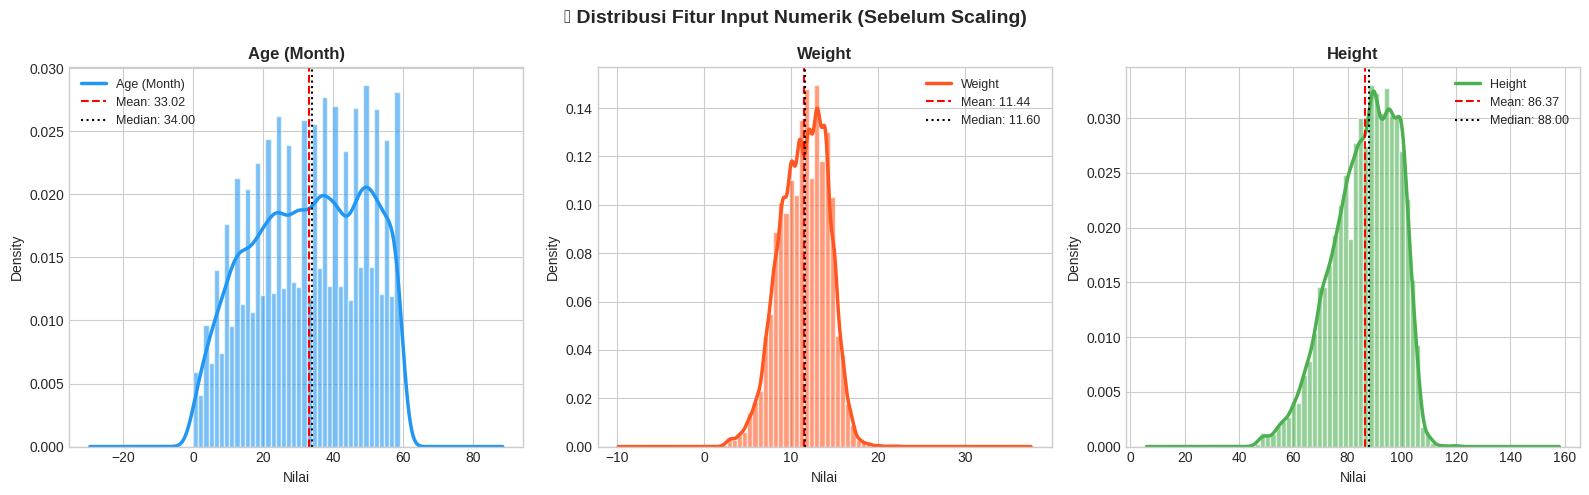

✅ Visualisasi tersimpan: viz_01_distribusi_fitur_input.png


In [15]:
# ─── 5.1 Histogram + KDE Distribusi Fitur Input Numerik ─────────────────────
palette_3 = [COLORS['primary'], COLORS['secondary'], COLORS['accent']]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('📊 Distribusi Fitur Input Numerik (Sebelum Scaling)',
             fontsize=14, fontweight='bold')

for ax, col, color in zip(axes, NUM_FEATURES, palette_3):
    data = df_clean[col].dropna()
    ax.hist(data, bins=40, alpha=0.6, color=color, edgecolor='white', density=True)
    data.plot.kde(ax=ax, color=color, linewidth=2.5)
    ax.axvline(data.mean(),   color='red',   linestyle='--', linewidth=1.5,
               label=f'Mean: {data.mean():.2f}')
    ax.axvline(data.median(), color='black', linestyle=':',  linewidth=1.5,
               label=f'Median: {data.median():.2f}')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('Nilai')
    ax.set_ylabel('Density')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('viz_01_distribusi_fitur_input.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Visualisasi tersimpan: viz_01_distribusi_fitur_input.png')

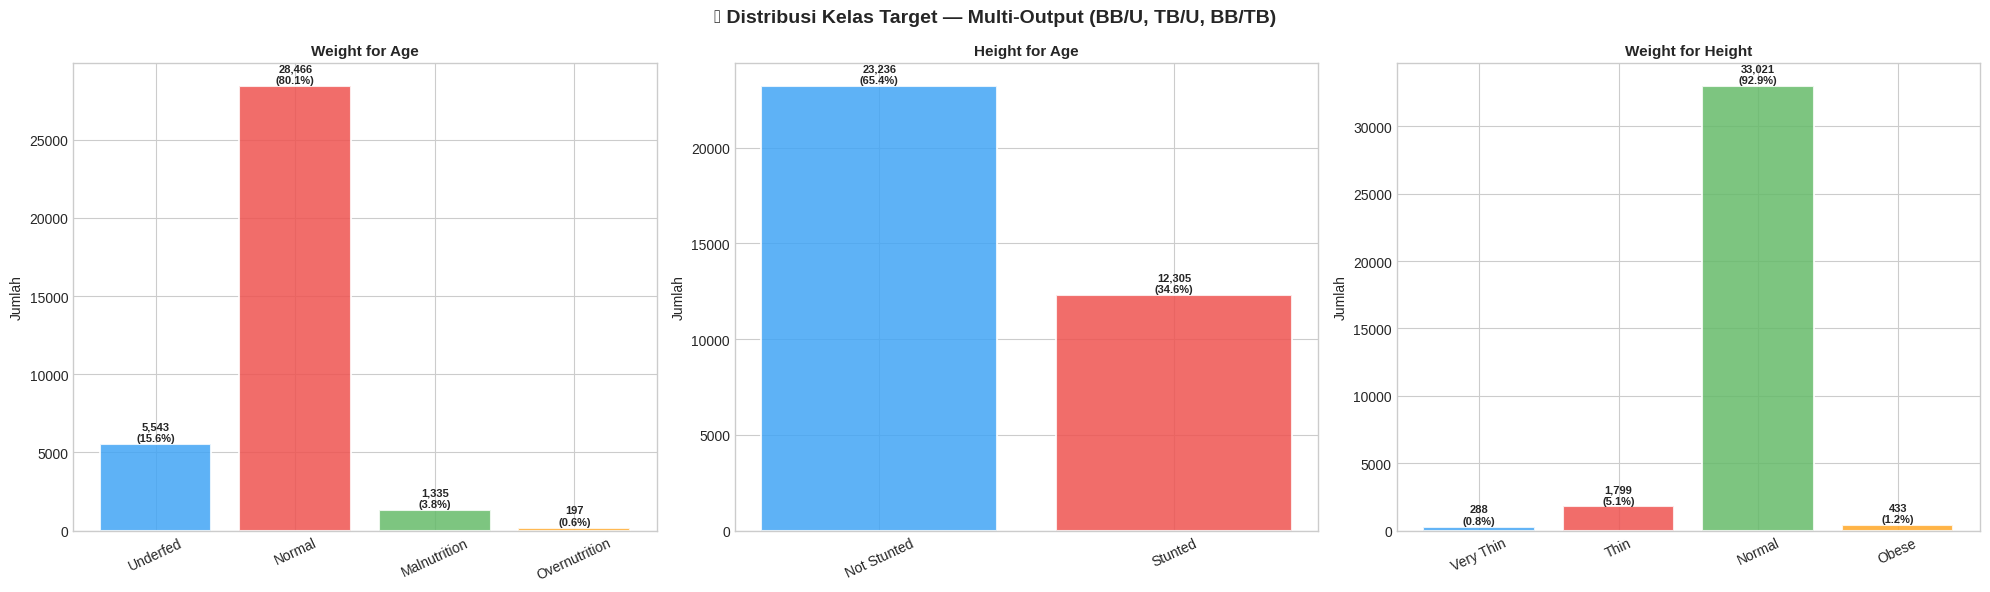

✅ Visualisasi tersimpan: viz_02_distribusi_target_multioutput.png
💡 Ketiga target menunjukkan ketidakseimbangan kelas → perlu SMOTE-NC


In [16]:
# ─── 5.2 Bar Chart Distribusi Kelas Target — Multi-Output ───────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('📊 Distribusi Kelas Target — Multi-Output (BB/U, TB/U, BB/TB)',
             fontsize=14, fontweight='bold')

bar_colors_list = ['#42A5F5', '#EF5350', '#66BB6A', '#FFA726']

for ax, col in zip(axes, TARGET_COLS):
    vc  = df_clean[col].value_counts().sort_index()
    lbl = [ENCODING_MAP[col].get(int(k), str(k)) for k in vc.index]
    bars = ax.bar(lbl, vc.values, color=bar_colors_list[:len(vc)],
                  alpha=0.85, edgecolor='white', linewidth=1.5)
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_ylabel('Jumlah')
    ax.tick_params(axis='x', rotation=25)
    for bar, v in zip(bars, vc.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                f'{v:,}\n({v/len(df_clean)*100:.1f}%)',
                ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('viz_02_distribusi_target_multioutput.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Visualisasi tersimpan: viz_02_distribusi_target_multioutput.png')
print('💡 Ketiga target menunjukkan ketidakseimbangan kelas → perlu SMOTE-NC')

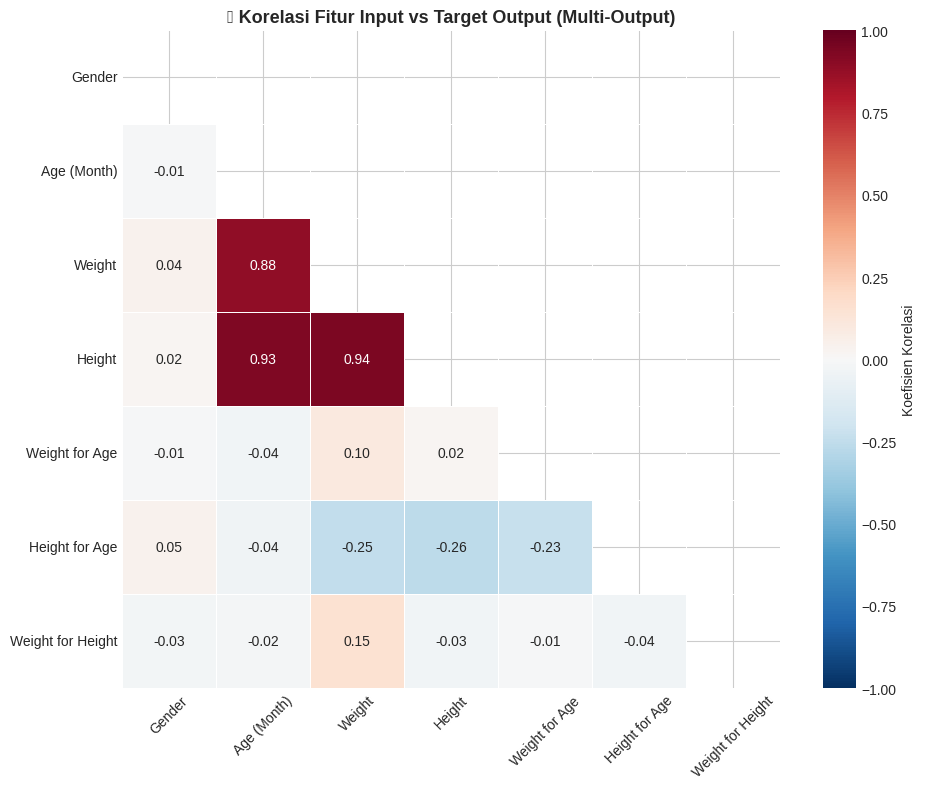

✅ Visualisasi tersimpan: viz_03_heatmap_korelasi.png


In [17]:
# ─── 5.3 Heatmap Korelasi ───────────────────────────────────────────────────
corr_cols = FEATURE_COLS + TARGET_COLS
corr_data = df_clean[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_data, dtype=bool))
sns.heatmap(corr_data, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            ax=ax, square=True, linewidths=0.5,
            cbar_kws={'label': 'Koefisien Korelasi'})
ax.set_title('🔥 Korelasi Fitur Input vs Target Output (Multi-Output)',
             fontsize=13, fontweight='bold')
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('viz_03_heatmap_korelasi.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Visualisasi tersimpan: viz_03_heatmap_korelasi.png')

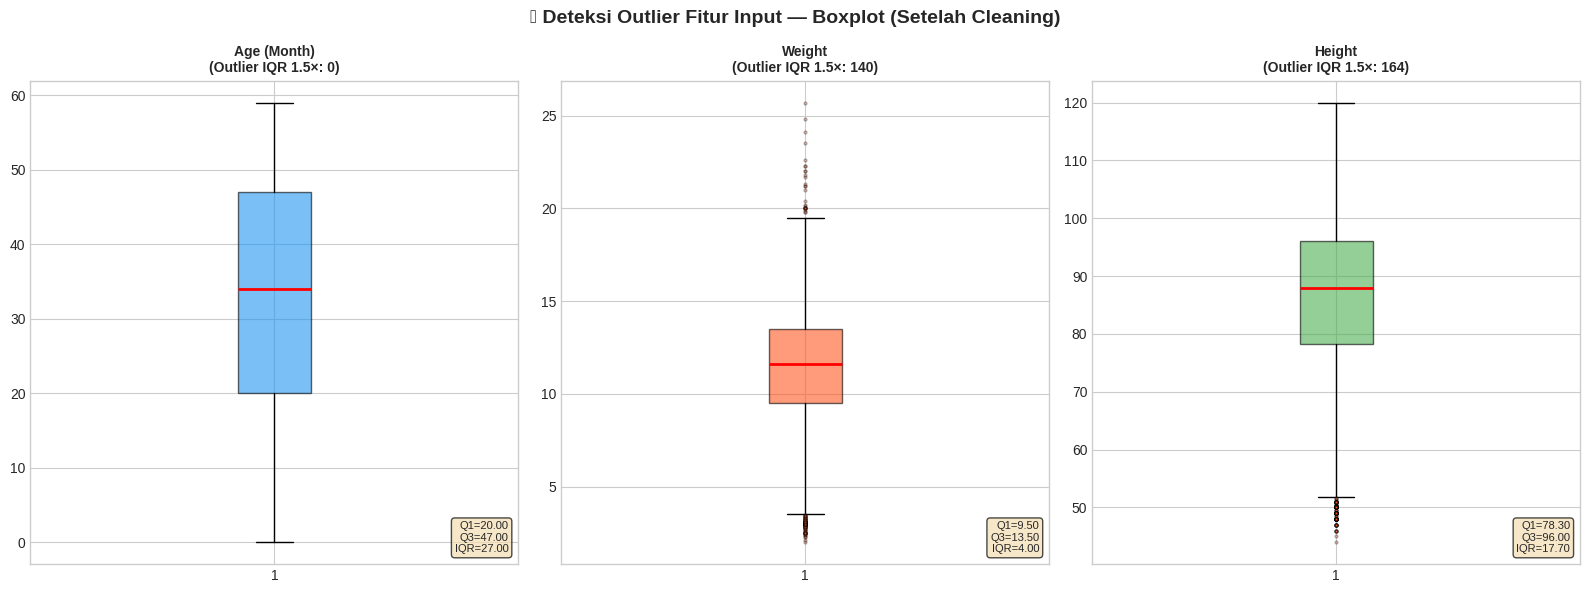

✅ Visualisasi tersimpan: viz_04_boxplot_outlier.png


In [18]:
# ─── 5.4 Boxplot Outlier Fitur Input ────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('📦 Deteksi Outlier Fitur Input — Boxplot (Setelah Cleaning)',
             fontsize=14, fontweight='bold')

for ax, col, color in zip(axes, NUM_FEATURES, palette_3):
    data = df_clean[col].dropna()
    ax.boxplot(data, patch_artist=True, vert=True,
               boxprops=dict(facecolor=color, alpha=0.6),
               medianprops=dict(color='red', linewidth=2),
               flierprops=dict(marker='o', markersize=2, alpha=0.3,
                               markerfacecolor=COLORS['secondary']))
    Q1, Q3 = data.quantile(0.25), data.quantile(0.75)
    IQR = Q3 - Q1
    n_out = ((data < Q1 - 1.5*IQR) | (data > Q3 + 1.5*IQR)).sum()
    ax.set_title(f'{col}\n(Outlier IQR 1.5×: {n_out:,})', fontsize=10, fontweight='bold')
    ax.text(0.98, 0.02, f'Q1={Q1:.2f}\nQ3={Q3:.2f}\nIQR={IQR:.2f}',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=8,
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))

plt.tight_layout()
plt.savefig('viz_04_boxplot_outlier.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Visualisasi tersimpan: viz_04_boxplot_outlier.png')

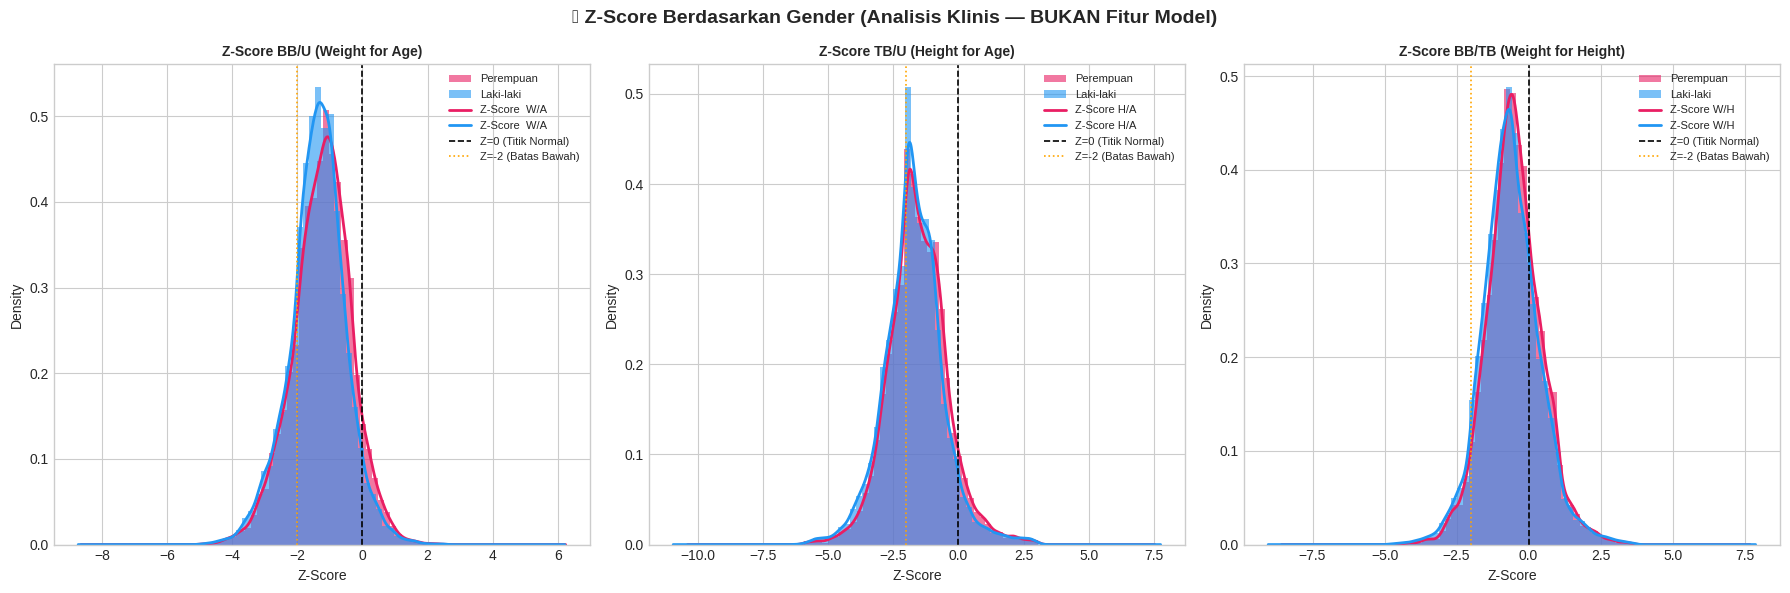

✅ Visualisasi tersimpan: viz_05_zscore_gender.png


In [19]:
# ─── 5.5 Distribusi Z-Score per Gender (Analisis Klinis) ────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('📊 Z-Score Berdasarkan Gender (Analisis Klinis — BUKAN Fitur Model)',
             fontsize=14, fontweight='bold')

zscore_cols  = ['Z-Score  W/A', 'Z-Score H/A', 'Z-Score W/H']
target_names = ['BB/U (Weight for Age)', 'TB/U (Height for Age)', 'BB/TB (Weight for Height)']

for ax, col, title in zip(axes, zscore_cols, target_names):
    data_f = df_clean[df_clean['Gender'] == 0][col]
    data_m = df_clean[df_clean['Gender'] == 1][col]
    ax.hist(data_f, bins=40, alpha=0.6, color='#E91E63', label='Perempuan', density=True)
    ax.hist(data_m, bins=40, alpha=0.6, color='#2196F3', label='Laki-laki',   density=True)
    data_f.plot.kde(ax=ax, color='#E91E63', linewidth=2)
    data_m.plot.kde(ax=ax, color='#2196F3', linewidth=2)
    ax.axvline(0,  color='black',  linestyle='--', linewidth=1.2, label='Z=0 (Titik Normal)')
    ax.axvline(-2, color='orange', linestyle=':',  linewidth=1.2, label='Z=-2 (Batas Bawah)')
    ax.set_title(f'Z-Score {title}', fontweight='bold', fontsize=10)
    ax.set_xlabel('Z-Score')
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('viz_05_zscore_gender.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Visualisasi tersimpan: viz_05_zscore_gender.png')

## ⚙️ 6. Feature Preparation — Siapkan Matriks X dan y

In [20]:
# ─── 6.1 Siapkan Matriks Fitur (X) dan Target (y) ──────────────────────────
# X = 4 fitur antropometri (BELUM discaling — scaling dilakukan setelah split)
# y = 3 label target multi-output

X = df_clean[FEATURE_COLS].copy()
y = df_clean[TARGET_COLS].copy()
for col in TARGET_COLS:
    y[col] = y[col].astype(int)

print(f'📌 Matriks fitur X  : {X.shape}  → {FEATURE_COLS}')
print(f'📌 Matriks target y : {y.shape}  → {TARGET_COLS}')
print()
print('Statistik X (sebelum scaling):')
print(X[NUM_FEATURES].describe().loc[['mean','std','min','max']].round(3).to_string())
print()
print('Fitur X (5 baris teratas):')
print(X.head())
print()
print('Target y (5 baris teratas):')
print(y.head())

📌 Matriks fitur X  : (35541, 4)  → ['Gender', 'Age (Month)', 'Weight', 'Height']
📌 Matriks target y : (35541, 3)  → ['Weight for Age', 'Height for Age', 'Weight for Height']

Statistik X (sebelum scaling):
      Age (Month)  Weight   Height
mean      33.0150 11.4400  86.3720
std       15.8810  2.7090  11.8730
min        0.0000  2.0000  44.0000
max       59.0000 25.7000 120.0000

Fitur X (5 baris teratas):
   Gender  Age (Month)  Weight  Height
0       0           54 13.2000 97.5000
1       1           44 12.0000 92.0000
2       1           57 14.0000 97.0000
3       1           26 11.0000 79.0000
4       0           59 14.6000 98.0000

Target y (5 baris teratas):
   Weight for Age  Height for Age  Weight for Height
0               1               1                  2
1               1               1                  2
2               1               1                  2
3               1               1                  2
4               1               1                  2


## ✂️ 7. Split Dataset

Membagi dataset sesuai metodologi penelitian:

| Split | Porsi | Kegunaan |
|---|---|---|
| **Training Set** | **60%** | Melatih model TabNet & MLP |
| **Testing Set** | **30%** | Evaluasi akhir / benchmarking model |
| **Validation Set** | **10%** | **Disimpan murni** — hanya untuk pengujian akhir pasca-deployment |

> ⚠️ **Validation Set Murni**: Data validation **tidak ikut dalam proses training maupun testing model**. Sesuai arahan dosen, validation set hanya digunakan untuk pengujian akhir pada kondisi nyata saat sistem sudah di-deploy.

> **Stratifikasi Multi-Output**: Label kombinasi dari 3 target digunakan agar distribusi kelas tetap proporsional di setiap split — penting terutama untuk kelas minoritas (Overnutrition: 0,7%).

In [21]:
# ─── 7.1 Buat Label Kombinasi untuk Stratifikasi ────────────────────────────
y_combined_label = (
    y['Weight for Age'].astype(str) + '_' +
    y['Height for Age'].astype(str) + '_' +
    y['Weight for Height'].astype(str)
)

print(f'📌 Label kombinasi unik: {y_combined_label.nunique()} kombinasi kelas')
print()
print('Top 10 kombinasi terbanyak:')
print(y_combined_label.value_counts().head(10).to_string())

📌 Label kombinasi unik: 21 kombinasi kelas

Top 10 kombinasi terbanyak:
1_0_2    21358
1_1_2     6389
0_1_2     4036
2_1_1      583
0_0_2      569
2_1_2      550
0_0_1      549
1_0_1      351
0_1_1      309
1_1_3      283


In [22]:
# ─── 7.2 Filter kombinasi label tunggal (tidak bisa distratifikasi) ─────────
class_counts        = y_combined_label.value_counts()
single_instance_cls = class_counts[class_counts < 2].index
mask_valid_split    = ~y_combined_label.isin(single_instance_cls)

X_filtered          = X[mask_valid_split]
y_filtered          = y[mask_valid_split]
y_combined_filtered = y_combined_label[mask_valid_split]

n_removed = len(y_combined_label) - len(y_combined_filtered)
print(f'📌 Baris dengan kombinasi label tunggal difilter: {n_removed}')

# ─── 7.3 TAHAP 1: Split Validation (10%) vs Train+Test (90%) ────────────────
# Validation set dipisah LEBIH DULU agar benar-benar murni dan terisolasi
print()
print('🔀 Tahap 1: Memisahkan Validation Set (10%) terlebih dahulu...')

X_traintest, X_val, y_traintest, y_val = train_test_split(
    X_filtered, y_filtered,
    test_size=0.10,        # 10% untuk validation
    random_state=42,
    stratify=y_combined_filtered
)

# Label kombinasi untuk split berikutnya
y_traintest_combined = (
    y_traintest['Weight for Age'].astype(str) + '_' +
    y_traintest['Height for Age'].astype(str) + '_' +
    y_traintest['Weight for Height'].astype(str)
)

print(f'  → Train+Test: {len(X_traintest):,} | Validation: {len(X_val):,}')

# ─── 7.4 TAHAP 2: Split Train (60%) vs Test (30%) dari sisa 90% ─────────────
print()
print('🔀 Tahap 2: Membagi sisa data menjadi Training (60%) dan Testing (30%)...')

# Filter kombinasi tunggal dari traintest
class_counts_tt     = y_traintest_combined.value_counts()
single_instance_tt  = class_counts_tt[class_counts_tt < 2].index
mask_valid_tt       = ~y_traintest_combined.isin(single_instance_tt)

X_traintest_f       = X_traintest[mask_valid_tt]
y_traintest_f       = y_traintest[mask_valid_tt]
y_combined_tt_f     = y_traintest_combined[mask_valid_tt]

n_removed_tt = len(y_traintest_combined) - len(y_combined_tt_f)
print(f'  → Baris traintest difilter (label tunggal): {n_removed_tt}')

X_train, X_test, y_train, y_test = train_test_split(
    X_traintest_f, y_traintest_f,
    test_size=(0.30 / 0.90),   # 30% dari total = 30/90 dari traintest
    random_state=42,
    stratify=y_combined_tt_f
)

total = len(X_filtered)
print()
print('=' * 62)
print('             ✂️  HASIL PEMBAGIAN DATASET v3.0')
print('=' * 62)
for name, X_, target_pct in [('Training',   X_train, '60%'),
                              ('Testing',    X_test,  '30%'),
                              ('Validation', X_val,   '10%')]:
    print(f'  {name:<12}: {len(X_):>7,} sampel ({len(X_)/total*100:.1f}%) — target: {target_pct}')
print(f'  {"TOTAL":<12}: {total:>7,} sampel')
print('=' * 62)
print()
print('⚠️  PENTING — Peran Setiap Split:')
print('   Training   → Digunakan untuk melatih model TabNet & MLP')
print('   Testing    → Evaluasi akhir performa model (setelah training selesai)')
print('   Validation → DISIMPAN MURNI — hanya untuk pengujian pasca-deployment')
print()
print('✅ Split selesai. Semua subset masih dalam skala ASLI (belum di-scale).')

📌 Baris dengan kombinasi label tunggal difilter: 1

🔀 Tahap 1: Memisahkan Validation Set (10%) terlebih dahulu...
  → Train+Test: 31,986 | Validation: 3,554

🔀 Tahap 2: Membagi sisa data menjadi Training (60%) dan Testing (30%)...
  → Baris traintest difilter (label tunggal): 0

             ✂️  HASIL PEMBAGIAN DATASET v3.0
  Training    :  21,324 sampel (60.0%) — target: 60%
  Testing     :  10,662 sampel (30.0%) — target: 30%
  Validation  :   3,554 sampel (10.0%) — target: 10%
  TOTAL       :  35,540 sampel

⚠️  PENTING — Peran Setiap Split:
   Training   → Digunakan untuk melatih model TabNet & MLP
   Testing    → Evaluasi akhir performa model (setelah training selesai)
   Validation → DISIMPAN MURNI — hanya untuk pengujian pasca-deployment

✅ Split selesai. Semua subset masih dalam skala ASLI (belum di-scale).


## 🧪 8. Verifikasi Distribusi & Chi-Square Test

In [23]:
# ─── 8.1 Distribusi Kelas per Split ─────────────────────────────────────────
print('📋 Verifikasi Distribusi Kelas Target per Split (Stratifikasi Multi-Output)')
print('=' * 80)

splits_dict = {
    'Full Data' : y_filtered,
    'Train'     : y_train,
    'Test'      : y_test,
    'Validation': y_val
}

for col in TARGET_COLS:
    print(f'\n  [{col}]')
    header = f'  {"Kelas":<38}' + ''.join(f'{n:>14}' for n in splits_dict.keys())
    print(header)
    print('  ' + '-' * (38 + 14 * len(splits_dict)))
    for cls in sorted(y_filtered[col].unique()):
        label = ENCODING_MAP[col].get(int(cls), str(cls))
        row   = f'  {str(int(cls)) + " " + label:<38}'
        for ys in splits_dict.values():
            pct  = (ys[col] == cls).sum() / len(ys) * 100
            row += f'{pct:>13.1f}%'
        print(row)

print()
print('✅ Distribusi kelas proporsional di semua split (stratifikasi berhasil)')

📋 Verifikasi Distribusi Kelas Target per Split (Stratifikasi Multi-Output)

  [Weight for Age]
  Kelas                                      Full Data         Train          Test    Validation
  ----------------------------------------------------------------------------------------------
  0 Underfed                                     15.6%         15.6%         15.6%         15.6%
  1 Normal                                       80.1%         80.1%         80.1%         80.1%
  2 Malnutrition                                  3.8%          3.8%          3.8%          3.7%
  3 Overnutrition                                 0.6%          0.6%          0.6%          0.6%

  [Height for Age]
  Kelas                                      Full Data         Train          Test    Validation
  ----------------------------------------------------------------------------------------------
  0 Not Stunted                                  65.4%         65.4%         65.4%         65.4%
  1 Stunted 

In [24]:
# ─── 8.2 Chi-Square Test — Verifikasi Kuantitatif Distribusi ────────────────
# [v3.0] Tambahan dari saran dokumentasi: verifikasi statistik distribusi kelas
# p-value > 0.05 → distribusi tidak berbeda signifikan (stratifikasi berhasil)

print('📊 CHI-SQUARE TEST — Verifikasi Distribusi Kelas antar Split')
print('=' * 65)
print('   Hipotesis: H0 = distribusi tidak berbeda signifikan (p > 0.05)')
print('   Interpretasi: p > 0.05 → ✅ stratifikasi berhasil')
print()

for col in TARGET_COLS:
    print(f'  [{col}]')
    classes = sorted(y_filtered[col].unique())

    for split_name, y_split in [('Train vs Test', (y_train, y_test)),
                                  ('Train vs Val',  (y_train, y_val)),
                                  ('Test  vs Val',  (y_test,  y_val))]:
        ya, yb = y_split
        counts_a = [(ya[col] == c).sum() for c in classes]
        counts_b = [(yb[col] == c).sum() for c in classes]
        contingency = np.array([counts_a, counts_b])

        # Hanya jalankan jika semua sel > 0
        if np.all(contingency > 0):
            chi2, p_value, _, _ = chi2_contingency(contingency)
            status = '✅ OK (tidak berbeda)' if p_value > 0.05 else '⚠️ Berbeda signifikan'
            print(f'    {split_name:<20}: chi2={chi2:.4f}, p={p_value:.4f}  {status}')
        else:
            print(f'    {split_name:<20}: ⚠️ Ada sel dengan count=0 (kelas sangat sedikit)')
    print()

📊 CHI-SQUARE TEST — Verifikasi Distribusi Kelas antar Split
   Hipotesis: H0 = distribusi tidak berbeda signifikan (p > 0.05)
   Interpretasi: p > 0.05 → ✅ stratifikasi berhasil

  [Weight for Age]
    Train vs Test       : chi2=0.0019, p=1.0000  ✅ OK (tidak berbeda)
    Train vs Val        : chi2=0.0068, p=0.9999  ✅ OK (tidak berbeda)
    Test  vs Val        : chi2=0.0073, p=0.9998  ✅ OK (tidak berbeda)

  [Height for Age]
    Train vs Test       : chi2=0.0004, p=0.9834  ✅ OK (tidak berbeda)
    Train vs Val        : chi2=0.0000, p=0.9978  ✅ OK (tidak berbeda)
    Test  vs Val        : chi2=0.0000, p=1.0000  ✅ OK (tidak berbeda)

  [Weight for Height]
    Train vs Test       : chi2=0.0364, p=0.9982  ✅ OK (tidak berbeda)
    Train vs Val        : chi2=0.0158, p=0.9995  ✅ OK (tidak berbeda)
    Test  vs Val        : chi2=0.0464, p=0.9974  ✅ OK (tidak berbeda)



## ⚙️ 9. StandardScaler — Fit pada X_train SAJA

> **Aturan kritis**: `StandardScaler` hanya boleh di-fit dari `X_train`.  
> `X_test` dan `X_val` hanya menggunakan `.transform()` — tidak boleh `.fit_transform()`.
> Melanggar aturan ini = **data leakage** (informasi statistik test/val bocor ke scaler).

In [25]:
# ─── 9.1 Fit StandardScaler HANYA pada X_train ─────────────────────────────
print('🔧 StandardScaler: Fit pada X_train → Transform X_test & X_val')
print('-' * 65)
print('   Alasan StandardScaler (bukan MinMaxScaler/RobustScaler):')
print('   - Menghasilkan mean=0, std=1 (sesuai rekomendasi paper TabNet)')
print('   - Lebih robust terhadap outlier dibanding MinMaxScaler')
print('   - Outlier pada fitur input sudah ditangani di step 4.5')
print('   - Gender biner [0/1] tidak distandarisasi')
print()

print('  Statistik SEBELUM standarisasi (dari X_train):')
print(X_train[NUM_FEATURES].describe().loc[['mean','std','min','max']].round(4).to_string())
print()

# ── Inisialisasi dan fit scaler dari X_train SAJA ──────────────────────────
scaler = StandardScaler()
scaler.fit(X_train[NUM_FEATURES])   # ← fit HANYA dari X_train

print('  Parameter scaler (dipelajari dari X_train):')
for col, mean_, std_ in zip(NUM_FEATURES, scaler.mean_, scaler.scale_):
    print(f'    {col:<15}: mean={mean_:.4f}, std={std_:.4f}')
print()

# ── Transform semua subset menggunakan scaler yang SAMA ────────────────────
X_train_scaled = X_train.copy()
X_train_scaled[NUM_FEATURES] = scaler.transform(X_train[NUM_FEATURES])

X_test_scaled = X_test.copy()
X_test_scaled[NUM_FEATURES]  = scaler.transform(X_test[NUM_FEATURES])    # .transform saja

X_val_scaled = X_val.copy()
X_val_scaled[NUM_FEATURES]   = scaler.transform(X_val[NUM_FEATURES])     # .transform saja

print('  Statistik SETELAH standarisasi (X_train_scaled):')
print(X_train_scaled[NUM_FEATURES].describe().loc[['mean','std','min','max']].round(4).to_string())
print()
print('  ✅ X_train_scaled : fit_transform — scaler belajar dari X_train')
print('  ✅ X_test_scaled  : transform only — tidak bocorkan info test ke scaler')
print('  ✅ X_val_scaled   : transform only — tidak bocorkan info val ke scaler')

# ── Simpan scaler menggunakan joblib (v3.0: ganti dari pickle) ─────────────
joblib.dump(scaler, 'standard_scaler.joblib')
print()
print('  ✅ StandardScaler disimpan: standard_scaler.joblib')
print('     [v3.0] Menggunakan joblib (rekomendasi resmi scikit-learn)')
print('     Cara load: scaler = joblib.load("standard_scaler.joblib")')

🔧 StandardScaler: Fit pada X_train → Transform X_test & X_val
-----------------------------------------------------------------
   Alasan StandardScaler (bukan MinMaxScaler/RobustScaler):
   - Menghasilkan mean=0, std=1 (sesuai rekomendasi paper TabNet)
   - Lebih robust terhadap outlier dibanding MinMaxScaler
   - Outlier pada fitur input sudah ditangani di step 4.5
   - Gender biner [0/1] tidak distandarisasi

  Statistik SEBELUM standarisasi (dari X_train):
      Age (Month)  Weight   Height
mean      33.0209 11.4465  86.3957
std       15.8544  2.7063  11.8478
min        0.0000  2.0000  46.0000
max       59.0000 25.7000 120.0000

  Parameter scaler (dipelajari dari X_train):
    Age (Month)    : mean=33.0209, std=15.8541
    Weight         : mean=11.4465, std=2.7062
    Height         : mean=86.3957, std=11.8475

  Statistik SETELAH standarisasi (X_train_scaled):
      Age (Month)  Weight  Height
mean      -0.0000 -0.0000 -0.0000
std        1.0000  1.0000  1.0000
min       -2.0828 -

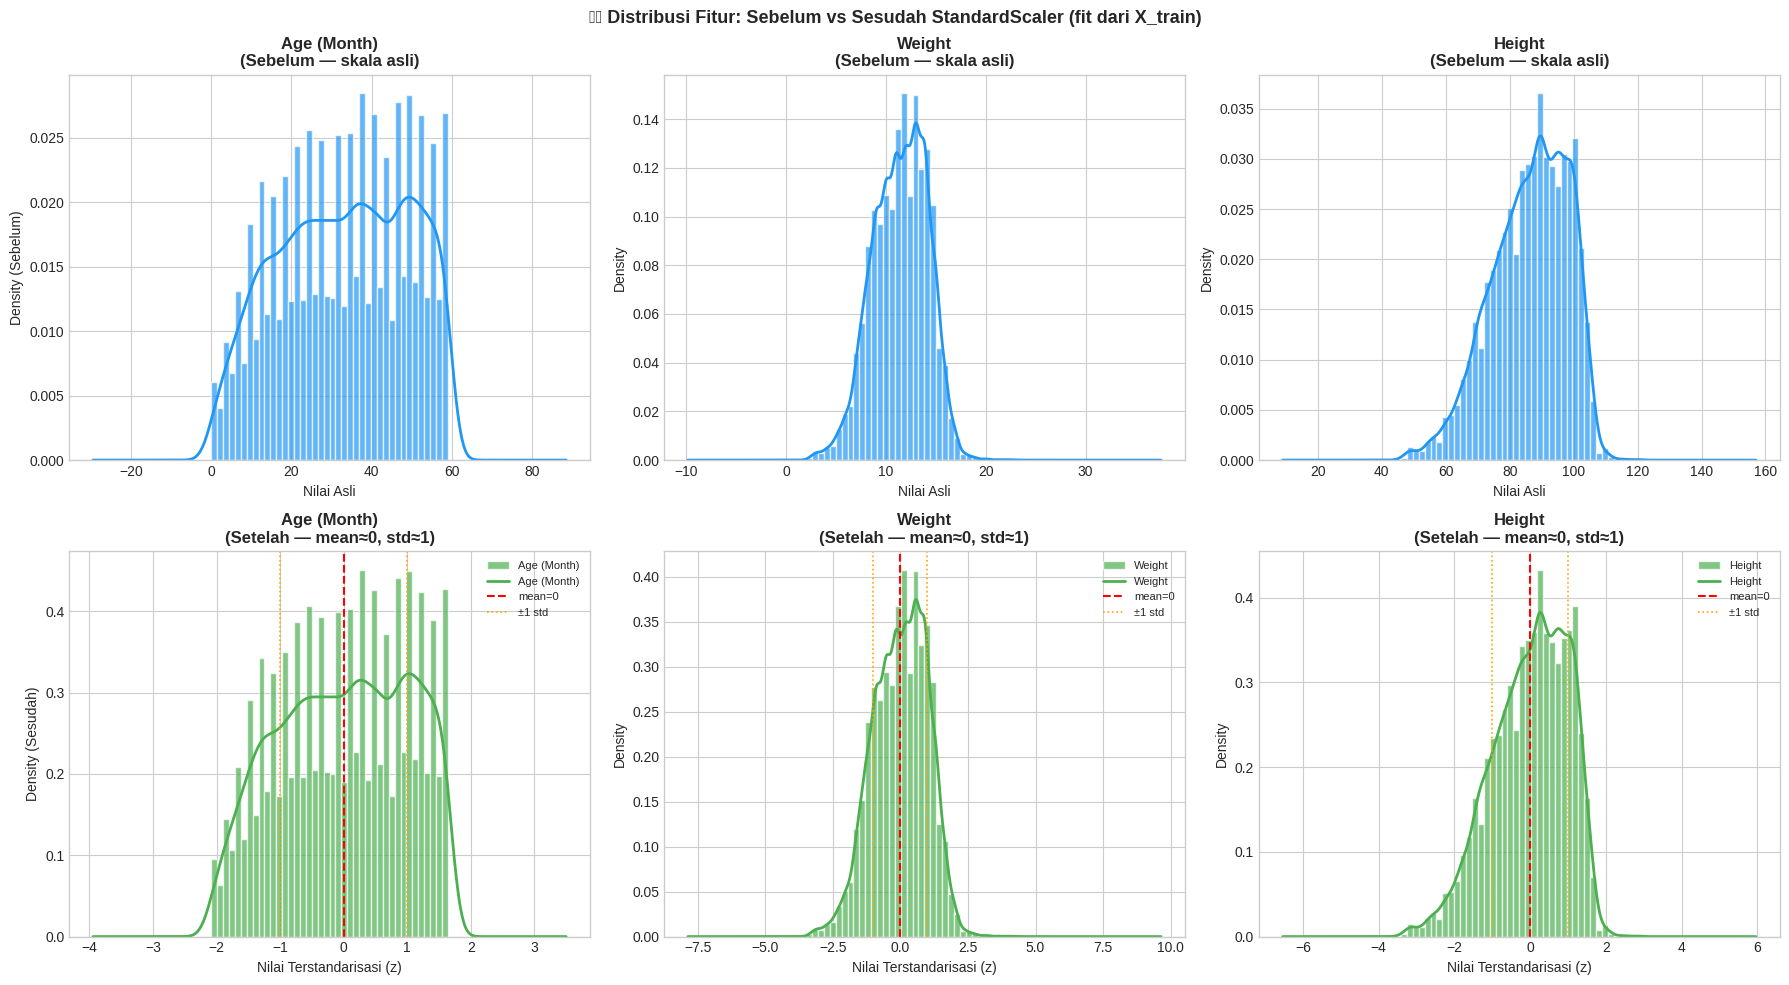

✅ Visualisasi tersimpan: viz_06_standardscaler_before_after.png


In [26]:
# ─── 9.2 Visualisasi Sebelum vs Sesudah StandardScaler ─────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('⚙️ Distribusi Fitur: Sebelum vs Sesudah StandardScaler (fit dari X_train)',
             fontsize=13, fontweight='bold')

for i, col in enumerate(NUM_FEATURES):
    ax0 = axes[0, i]
    X_train[col].plot.hist(bins=40, ax=ax0, color=COLORS['primary'], alpha=0.7,
                           edgecolor='white', density=True)
    X_train[col].plot.kde(ax=ax0, color=COLORS['primary'], linewidth=2)
    ax0.set_title(f'{col}\n(Sebelum — skala asli)', fontweight='bold')
    ax0.set_xlabel('Nilai Asli')

    ax1 = axes[1, i]
    X_train_scaled[col].plot.hist(bins=40, ax=ax1, color=COLORS['accent'], alpha=0.7,
                                   edgecolor='white', density=True)
    X_train_scaled[col].plot.kde(ax=ax1, color=COLORS['accent'], linewidth=2)
    ax1.axvline(0,  color='red',    linestyle='--', linewidth=1.5, label='mean=0')
    ax1.axvline(1,  color='orange', linestyle=':',  linewidth=1.2, label='±1 std')
    ax1.axvline(-1, color='orange', linestyle=':',  linewidth=1.2)
    ax1.set_title(f'{col}\n(Setelah — mean≈0, std≈1)', fontweight='bold')
    ax1.set_xlabel('Nilai Terstandarisasi (z)')
    ax1.legend(fontsize=8)

axes[0, 0].set_ylabel('Density (Sebelum)')
axes[1, 0].set_ylabel('Density (Sesudah)')

plt.tight_layout()
plt.savefig('viz_06_standardscaler_before_after.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Visualisasi tersimpan: viz_06_standardscaler_before_after.png')

## 🌳 10. Feature Importance Analysis

> **[v3.0 — Tambahan]** Analisis feature importance menggunakan RandomForest untuk memvalidasi bahwa keempat fitur yang dipilih memang informatif dan berkontribusi terhadap prediksi. Dilakukan **sebelum SMOTE** menggunakan data training yang bersih.

In [27]:
# ─── 10.1 RandomForest untuk Estimasi Feature Importance ────────────────────
print('🌳 Feature Importance Analysis (RandomForest Multi-Output)')
print('=' * 60)
print('   Tujuan: Memvalidasi bahwa keempat fitur berkontribusi signifikan')
print('   Data : X_train_scaled (sebelum SMOTE) — data asli, tidak ada sintetis')
print()

# RandomForest multi-output
rf_base = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)
rf_model = MultiOutputClassifier(rf_base)
rf_model.fit(X_train_scaled, y_train)

# Rata-rata feature importance dari semua target
importance_per_target = np.array(
    [est.feature_importances_ for est in rf_model.estimators_]
)
mean_importance = importance_per_target.mean(axis=0)
std_importance  = importance_per_target.std(axis=0)

importance_df = pd.DataFrame({
    'Fitur'       : FEATURE_COLS,
    'Importance'  : mean_importance,
    'Std'         : std_importance
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print('  Feature Importance (rata-rata dari 3 target):')
print(f'  {"Rank":<6}{"Fitur":<20}{"Importance":>12}{"Std":>10}')
print('  ' + '-' * 48)
for i, row in importance_df.iterrows():
    bar = '█' * int(row['Importance'] * 50)
    print(f'  {i+1:<6}{row["Fitur"]:<20}{row["Importance"]:>12.4f}{row["Std"]:>10.4f}  {bar}')

print()

# Importance per target
print('  Feature Importance per Target:')
print(f'  {"Fitur":<20}', end='')
for col in TARGET_COLS:
    print(f'{col[:12]:>14}', end='')
print()
print('  ' + '-' * (20 + 14 * len(TARGET_COLS)))
for j, feat in enumerate(FEATURE_COLS):
    print(f'  {feat:<20}', end='')
    for i in range(len(TARGET_COLS)):
        print(f'{importance_per_target[i][j]:>14.4f}', end='')
    print()

🌳 Feature Importance Analysis (RandomForest Multi-Output)
   Tujuan: Memvalidasi bahwa keempat fitur berkontribusi signifikan
   Data : X_train_scaled (sebelum SMOTE) — data asli, tidak ada sintetis

  Feature Importance (rata-rata dari 3 target):
  Rank  Fitur                 Importance       Std
  ------------------------------------------------
  1     Age (Month)               0.3270    0.1471  ████████████████
  2     Height                    0.3232    0.1603  ████████████████
  3     Weight                    0.3223    0.1448  ████████████████
  4     Gender                    0.0275    0.0060  █

  Feature Importance per Target:
  Fitur                 Weight for A  Height for A  Weight for H
  --------------------------------------------------------------
  Gender                      0.0355        0.0210        0.0261
  Age (Month)                 0.4202        0.4415        0.1193
  Weight                      0.4470        0.1193        0.4006
  Height                      

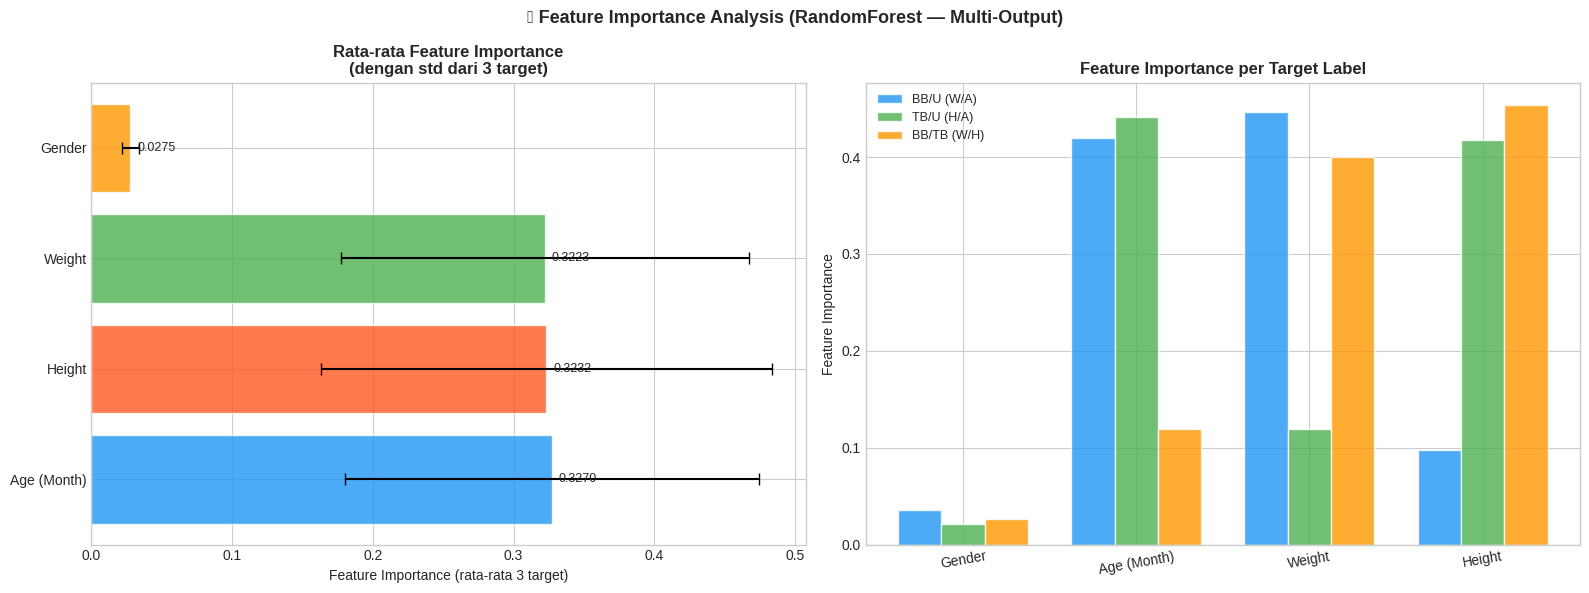

✅ Visualisasi tersimpan: viz_07_feature_importance.png

💡 Interpretasi:
   Fitur paling informatif : Age (Month)
   Importance terkecil     : 0.0275 — ⚠️ Pertimbangkan eliminasi fitur redundan


In [28]:
# ─── 10.2 Visualisasi Feature Importance ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('🌳 Feature Importance Analysis (RandomForest — Multi-Output)',
             fontsize=13, fontweight='bold')

# Panel kiri: rata-rata dengan error bar
ax0 = axes[0]
colors_fi = [COLORS['primary'], COLORS['secondary'], COLORS['accent'], COLORS['warning']]
bars = ax0.barh(importance_df['Fitur'], importance_df['Importance'],
                xerr=importance_df['Std'], capsize=4,
                color=colors_fi[:len(importance_df)], alpha=0.8, edgecolor='white')
ax0.set_xlabel('Feature Importance (rata-rata 3 target)')
ax0.set_title('Rata-rata Feature Importance\n(dengan std dari 3 target)', fontweight='bold')
for bar, val in zip(bars, importance_df['Importance']):
    ax0.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=9)

# Panel kanan: importance per target (grouped)
ax1 = axes[1]
x = np.arange(len(FEATURE_COLS))
w = 0.25
short_labels = ['BB/U (W/A)', 'TB/U (H/A)', 'BB/TB (W/H)']
colors_target = [COLORS['primary'], COLORS['accent'], COLORS['warning']]
for i, (col, clr, lbl) in enumerate(zip(TARGET_COLS, colors_target, short_labels)):
    ax1.bar(x + (i - 1) * w, importance_per_target[i], w,
            label=lbl, color=clr, alpha=0.8, edgecolor='white')
ax1.set_xticks(x)
ax1.set_xticklabels(FEATURE_COLS, rotation=10)
ax1.set_ylabel('Feature Importance')
ax1.set_title('Feature Importance per Target Label', fontweight='bold')
ax1.legend(fontsize=9)

plt.tight_layout()
plt.savefig('viz_07_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Visualisasi tersimpan: viz_07_feature_importance.png')

# Interpretasi
top_feature = importance_df.iloc[0]['Fitur']
min_imp     = importance_df['Importance'].min()
print()
print('💡 Interpretasi:')
print(f'   Fitur paling informatif : {top_feature}')
print(f'   Importance terkecil     : {min_imp:.4f} — {"✅ Semua fitur berkontribusi signifikan" if min_imp > 0.05 else "⚠️ Pertimbangkan eliminasi fitur redundan"}')

## ⚖️ 11. Oversampling dengan SMOTE-NC

**SMOTE-NC** *(Synthetic Minority Over-sampling Technique for Nominal and Continuous)*
mengatasi ketidakseimbangan kelas pada dataset campuran numerik + kategorik.

| Aturan | Detail |
|---|---|
| **Data target SMOTE-NC** | Hanya `X_train_scaled` — tidak boleh test atau validation |
| **Alasan** | Test & val harus mencerminkan distribusi nyata; data sintetis pada test/val = data leakage |
| **Strategi** | Label kombinasi 3 target → oversample kombinasi minoritas ke 30% mayoritas |

In [29]:
# ─── 11.1 Analisis Ketimpangan Kelas Sebelum SMOTE-NC ────────────────────────
print('📊 DISTRIBUSI KELAS SEBELUM SMOTE-NC (Training Set Scaled)')
print('=' * 65)

for col in TARGET_COLS:
    vc = y_train[col].value_counts().sort_index()
    ir = vc.max() / vc.min() if vc.min() > 0 else float('inf')
    print(f'\n  [{col}]  — Imbalance Ratio: {ir:.1f}x {"⚠️ PARAH" if ir > 10 else "⚠️ MODERAT"}')
    for cls, count in vc.items():
        label = ENCODING_MAP[col].get(int(cls), str(cls))
        pct   = count / len(y_train) * 100
        bar   = '█' * int(pct / 3)
        print(f'    Kelas {int(cls)} [{label:<35}]: {count:>6,} ({pct:5.2f}%) {bar}')

# Buat label kombinasi untuk SMOTE
y_train_combined = (
    y_train['Weight for Age'].astype(str) + '_' +
    y_train['Height for Age'].astype(str) + '_' +
    y_train['Weight for Height'].astype(str)
)
print(f'\n  Kombinasi label unik di training: {y_train_combined.nunique()}')
print('  Top 8 kombinasi:')
print(y_train_combined.value_counts().head(8).to_string())

📊 DISTRIBUSI KELAS SEBELUM SMOTE-NC (Training Set Scaled)

  [Weight for Age]  — Imbalance Ratio: 144.8x ⚠️ PARAH
    Kelas 0 [Underfed                           ]:  3,325 (15.59%) █████
    Kelas 1 [Normal                             ]: 17,081 (80.10%) ██████████████████████████
    Kelas 2 [Malnutrition                       ]:    800 ( 3.75%) █
    Kelas 3 [Overnutrition                      ]:    118 ( 0.55%) 

  [Height for Age]  — Imbalance Ratio: 1.9x ⚠️ MODERAT
    Kelas 0 [Not Stunted                        ]: 13,940 (65.37%) █████████████████████
    Kelas 1 [Stunted                            ]:  7,384 (34.63%) ███████████

  [Weight for Height]  — Imbalance Ratio: 115.2x ⚠️ PARAH
    Kelas 0 [Very Thin                          ]:    172 ( 0.81%) 
    Kelas 1 [Thin                               ]:  1,079 ( 5.06%) █
    Kelas 2 [Normal                             ]: 19,813 (92.91%) ██████████████████████████████
    Kelas 3 [Obese                              ]:    260 ( 1.22

In [30]:
# ─── 11.2 Konfigurasi SMOTE-NC ───────────────────────────────────────────────
try:
    from imblearn.over_sampling import SMOTENC
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                           'imbalanced-learn', '-q', '--break-system-packages'])
    from imblearn.over_sampling import SMOTENC

print('✅ imbalanced-learn berhasil diimport')
print()

# Gender (indeks 0) adalah satu-satunya fitur kategorik biner
FEATURE_LIST    = list(X_train_scaled.columns)
categorical_idx = [FEATURE_LIST.index('Gender')]

print('📌 Konfigurasi SMOTE-NC:')
print(f'   Fitur input       : {FEATURE_LIST}')
print(f'   Fitur kategorik   : Gender (indeks {categorical_idx})')
print(f'   Fitur numerik     : {[c for c in FEATURE_LIST if c != "Gender"]}')
print()

# Sampling strategy: target 30% dari kelas mayoritas
vc_combined    = y_train_combined.value_counts()
majority_count = vc_combined.max()
threshold      = int(majority_count * 0.30)

sampling_strategy = {
    combo: threshold
    for combo, count in vc_combined.items()
    if count < threshold
}

print(f'  Jumlah training   : {len(y_train):,} sampel')
print(f'  Mayoritas         : {vc_combined.idxmax()} ({majority_count:,} sampel)')
print(f'  Target minimum    : {threshold:,} sampel per kombinasi (30% mayoritas)')
print(f'  Kombinasi di-oversample: {len(sampling_strategy)}')
for k, v in list(sampling_strategy.items())[:5]:
    print(f'    {k}: {vc_combined[k]:,} → {v:,} (+{v - vc_combined[k]:,})')
if len(sampling_strategy) > 5:
    print(f'    ... dan {len(sampling_strategy) - 5} kombinasi lainnya')

✅ imbalanced-learn berhasil diimport

📌 Konfigurasi SMOTE-NC:
   Fitur input       : ['Gender', 'Age (Month)', 'Weight', 'Height']
   Fitur kategorik   : Gender (indeks [0])
   Fitur numerik     : ['Age (Month)', 'Weight', 'Height']

  Jumlah training   : 21,324 sampel
  Mayoritas         : 1_0_2 (12,815 sampel)
  Target minimum    : 3,844 sampel per kombinasi (30% mayoritas)
  Kombinasi di-oversample: 19
    1_1_2: 3,834 → 3,844 (+10)
    0_1_2: 2,422 → 3,844 (+1,422)
    2_1_1: 350 → 3,844 (+3,494)
    0_0_2: 341 → 3,844 (+3,503)
    2_1_2: 330 → 3,844 (+3,514)
    ... dan 14 kombinasi lainnya


In [31]:
# ─── 11.3 Terapkan SMOTE-NC ──────────────────────────────────────────────────
print('⏳ Menerapkan SMOTE-NC pada training set...')
t0 = time.time()

smote_nc = SMOTENC(
    categorical_features = categorical_idx,
    sampling_strategy    = sampling_strategy,
    random_state         = 42,
    k_neighbors          = 3    # k=3: aman untuk kelas dengan sedikit sampel (n<5)
)

X_train_arr          = X_train_scaled.values
y_train_combined_arr = y_train_combined.values

X_train_sm, y_train_sm_combined = smote_nc.fit_resample(
    X_train_arr, y_train_combined_arr
)

# Konversi kembali ke DataFrame
X_train_smote = pd.DataFrame(X_train_sm, columns=FEATURE_LIST)

# Decode label kombinasi → 3 kolom target
y_train_smote = pd.DataFrame(
    [str(s).split('_') for s in y_train_sm_combined],
    columns=TARGET_COLS
).astype(int)

# Pastikan Gender biner (0 atau 1)
X_train_smote['Gender'] = X_train_smote['Gender'].round().astype(int).clip(0, 1)

elapsed = time.time() - t0
print(f'✅ SMOTE-NC selesai dalam {elapsed:.2f} detik!')
print()
print(f'  X_train sebelum SMOTE : {X_train_scaled.shape}')
print(f'  X_train setelah SMOTE : {X_train_smote.shape}')
print(f'  Sampel sintetis       : +{len(X_train_smote) - len(X_train_scaled):,} ditambahkan')

# ─── Validasi Kualitas Data Sintetis ────────────────────────────────────────
print()
print('🔬 VALIDASI KUALITAS DATA SINTETIS (SMOTE-NC)')
print('=' * 60)

null_count = X_train_smote.isnull().sum().sum()
print(f'  Missing values setelah SMOTE  : {null_count}  {"✅ Bersih" if null_count == 0 else "❌ Ada missing!"}')

g_vals  = sorted(X_train_smote['Gender'].unique())
valid_g = all(v in [0, 1] for v in g_vals)
print(f'  Nilai Gender unik             : {g_vals}  {"✅ Valid (0/1)" if valid_g else "❌ Di luar rentang!"}')

print(f'\n  Perbandingan Mean Fitur (Asli vs Setelah SMOTE):')
print(f'  {"Fitur":<15} {"Mean Asli":>12} {"Mean SMOTE":>12} {"Selisih":>8} Status')
print('  ' + '-' * 55)
for col in NUM_FEATURES:
    m_orig  = X_train_scaled[col].mean()
    m_smote = X_train_smote[col].mean()
    diff    = abs(m_smote - m_orig)
    status  = '✅' if diff < 0.5 else '⚠️ Perlu diperiksa'
    print(f'  {col:<15} {m_orig:>12.4f} {m_smote:>12.4f} {diff:>8.4f}  {status}')

print()
print('✅ Validasi selesai — data sintetis siap digunakan')

⏳ Menerapkan SMOTE-NC pada training set...
✅ SMOTE-NC selesai dalam 2.41 detik!

  X_train sebelum SMOTE : (21324, 4)
  X_train setelah SMOTE : (85851, 4)
  Sampel sintetis       : +64,527 ditambahkan

🔬 VALIDASI KUALITAS DATA SINTETIS (SMOTE-NC)
  Missing values setelah SMOTE  : 0  ✅ Bersih
  Nilai Gender unik             : [np.int64(0), np.int64(1)]  ✅ Valid (0/1)

  Perbandingan Mean Fitur (Asli vs Setelah SMOTE):
  Fitur              Mean Asli   Mean SMOTE  Selisih Status
  -------------------------------------------------------
  Age (Month)          -0.0000      -0.2810   0.2810  ✅
  Weight               -0.0000      -0.3706   0.3706  ✅
  Height               -0.0000      -0.3223   0.3223  ✅

✅ Validasi selesai — data sintetis siap digunakan


In [32]:
# ─── 11.4 Distribusi Kelas Setelah SMOTE-NC ──────────────────────────────────
print('📊 DISTRIBUSI KELAS SETELAH SMOTE-NC (Training Set)')
print('=' * 65)

for col in TARGET_COLS:
    vc_b = y_train[col].value_counts().sort_index()
    vc_a = y_train_smote[col].value_counts().sort_index()
    ir_b = vc_b.max() / vc_b.min()
    ir_a = vc_a.max() / vc_a.min()
    pct_imp = (1 - ir_a / ir_b) * 100
    print(f'\n  [{col}]  IR: {ir_b:.1f}x → {ir_a:.1f}x  ({pct_imp:.1f}% lebih seimbang)')
    for cls in sorted(y_train_smote[col].unique()):
        label  = ENCODING_MAP[col].get(cls, str(cls))
        before = vc_b.get(cls, 0)
        after  = vc_a.get(cls, 0)
        pct    = after / len(y_train_smote) * 100
        added  = after - before
        marker = f'+{added:,}' if added > 0 else '(tidak berubah)'
        print(f'    Kelas {cls} [{label:<35}]: {after:>6,} ({pct:5.2f}%) [{marker}]')

print()
print('📌 Testing & Validation set TIDAK diubah — data asli terjaga')
print(f'  ✅ Test set       : {len(X_test_scaled):,} sampel (data asli, scaled)')
print(f'  ✅ Validation set : {len(X_val_scaled):,} sampel (data asli, scaled — MURNI)')

📊 DISTRIBUSI KELAS SETELAH SMOTE-NC (Training Set)

  [Weight for Age]  IR: 144.8x → 2.8x  (98.1% lebih seimbang)
    Kelas 0 [Underfed                           ]: 23,064 (26.87%) [+19,739]
    Kelas 1 [Normal                             ]: 32,035 (37.31%) [+14,954]
    Kelas 2 [Malnutrition                       ]: 19,220 (22.39%) [+18,420]
    Kelas 3 [Overnutrition                      ]: 11,532 (13.43%) [+11,414]

  [Height for Age]  IR: 1.9x → 1.5x  (21.5% lebih seimbang)
    Kelas 0 [Not Stunted                        ]: 51,255 (59.70%) [+37,315]
    Kelas 1 [Stunted                            ]: 34,596 (40.30%) [+27,212]

  [Weight for Height]  IR: 115.2x → 2.1x  (98.2% lebih seimbang)
    Kelas 0 [Very Thin                          ]: 15,376 (17.91%) [+15,204]
    Kelas 1 [Thin                               ]: 19,220 (22.39%) [+18,141]
    Kelas 2 [Normal                             ]: 32,035 (37.31%) [+12,222]
    Kelas 3 [Obese                              ]: 19,220 (22.39%)

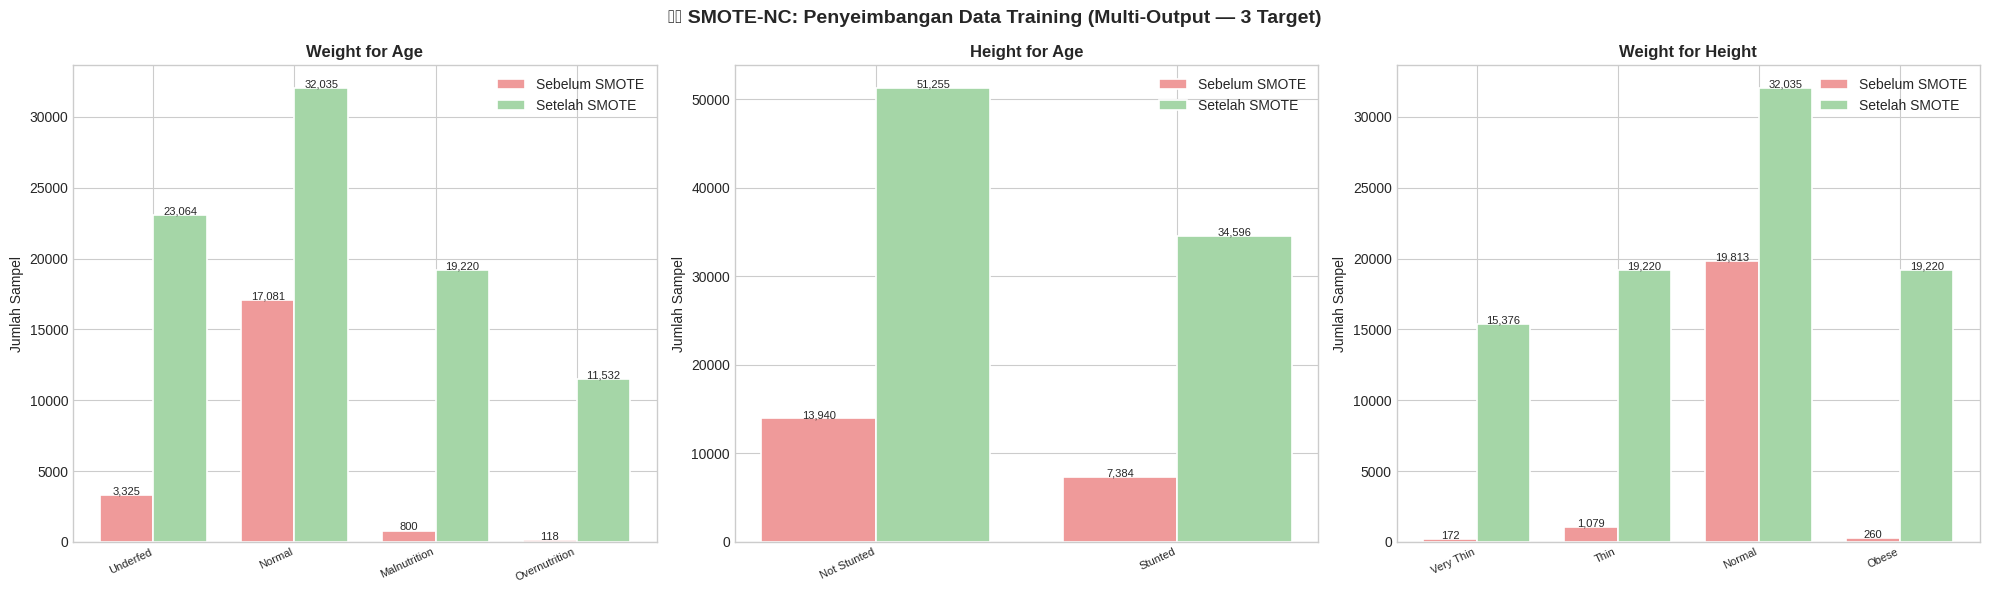

✅ Visualisasi tersimpan: viz_08_smotenc_multioutput.png


In [33]:
# ─── 11.5 Visualisasi SMOTE-NC Multi-Output ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('⚖️ SMOTE-NC: Penyeimbangan Data Training (Multi-Output — 3 Target)',
             fontsize=14, fontweight='bold')

for ax_idx, col in enumerate(TARGET_COLS):
    ax    = axes[ax_idx]
    vc_b  = y_train[col].value_counts().sort_index()
    vc_a  = y_train_smote[col].value_counts().sort_index()
    cls_labels = [ENCODING_MAP[col].get(int(k), str(k)) for k in vc_b.index]
    x = np.arange(len(cls_labels))
    w = 0.38

    b1 = ax.bar(x - w/2, vc_b.values, w, label='Sebelum SMOTE',
                 color='#EF9A9A', edgecolor='white', linewidth=1.2)
    b2 = ax.bar(x + w/2, [vc_a.get(k, 0) for k in vc_b.index], w,
                 label='Setelah SMOTE', color='#A5D6A7', edgecolor='white', linewidth=1.2)

    for bar, v in zip(b1, vc_b.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                f'{v:,}', ha='center', fontsize=8)
    for bar, k in zip(b2, vc_b.index):
        v = vc_a.get(k, 0)
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                f'{v:,}', ha='center', fontsize=8)

    ax.set_title(col, fontweight='bold')
    ax.set_ylabel('Jumlah Sampel')
    ax.set_xticks(x)
    ax.set_xticklabels(cls_labels, rotation=25, ha='right', fontsize=8)
    ax.legend()

plt.tight_layout()
plt.savefig('viz_08_smotenc_multioutput.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Visualisasi tersimpan: viz_08_smotenc_multioutput.png')

[v3.0] Visualisasi Distribusi Fitur: Sebelum vs Setelah SMOTE-NC


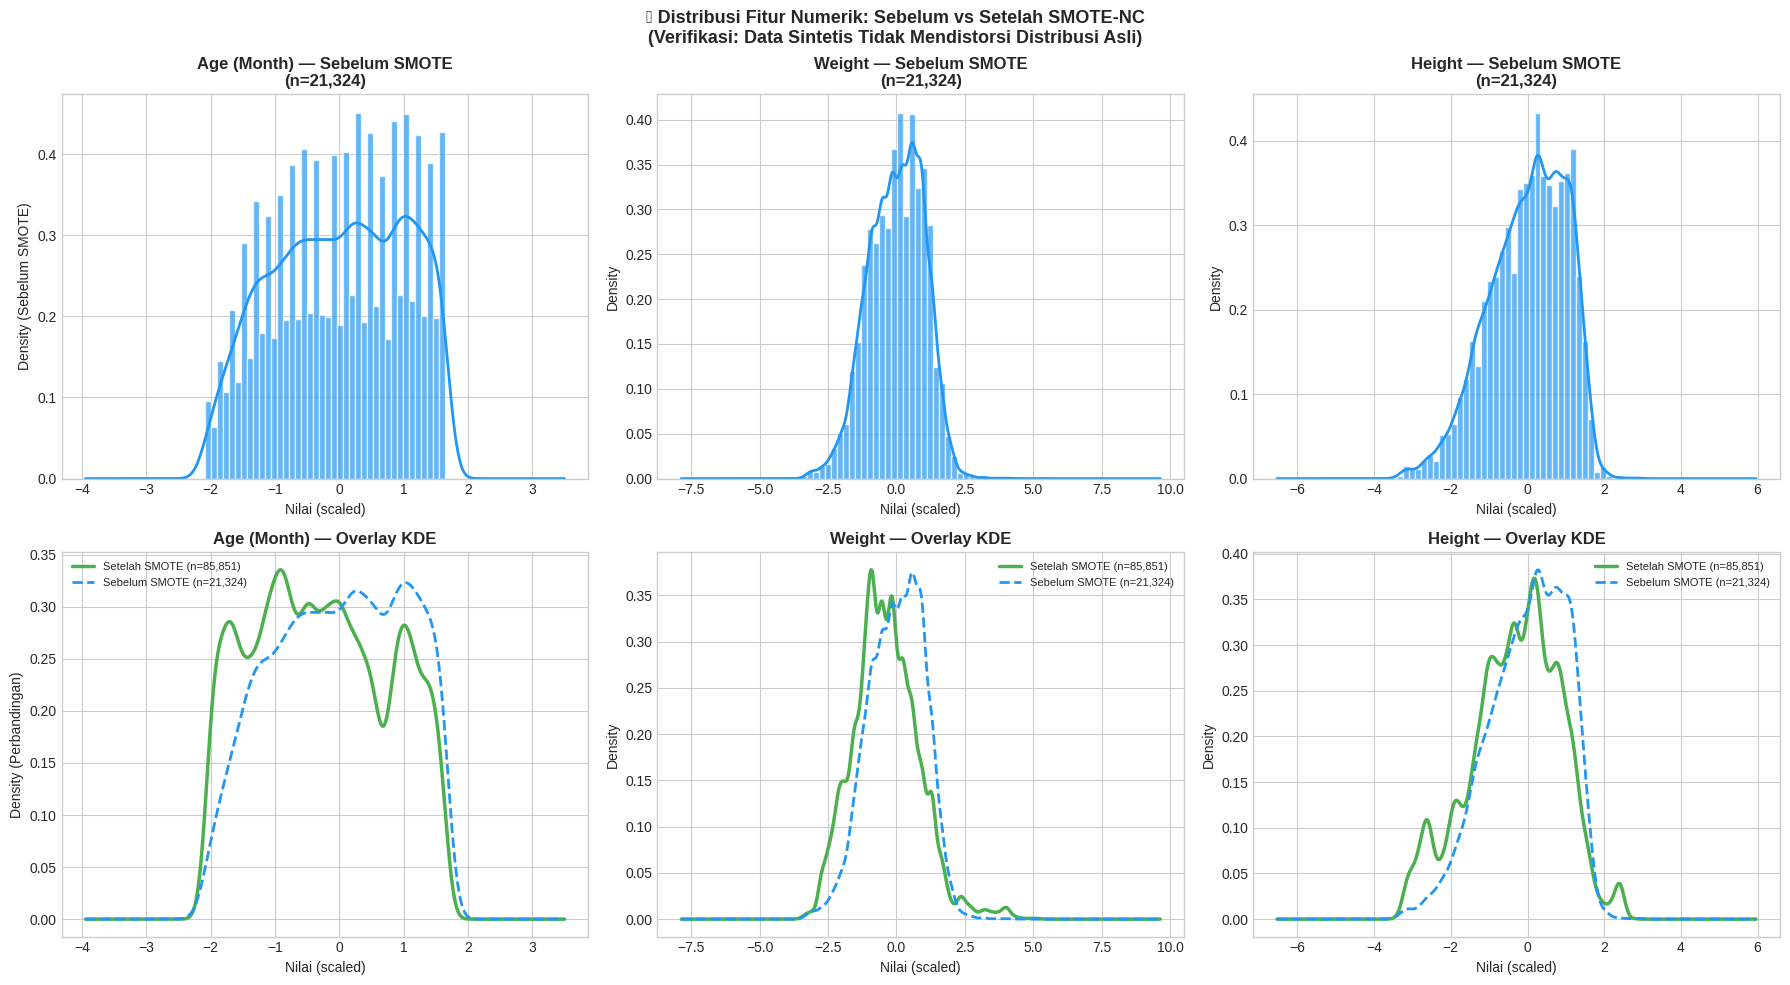

✅ Visualisasi tersimpan: viz_09_smote_fitur_distribusi.png
💡 Kurva yang overlap mendekati sempurna → data sintetis tidak mendistorsi distribusi ✅


In [34]:
# ─── 11.6 [v3.0] Distribusi Fitur Numerik Sebelum vs Setelah SMOTE ──────────
# Memverifikasi bahwa data sintetis tidak mendistorsi distribusi fitur asli
print('[v3.0] Visualisasi Distribusi Fitur: Sebelum vs Setelah SMOTE-NC')

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('🔬 Distribusi Fitur Numerik: Sebelum vs Setelah SMOTE-NC\n'
             '(Verifikasi: Data Sintetis Tidak Mendistorsi Distribusi Asli)',
             fontsize=13, fontweight='bold')

for i, col in enumerate(NUM_FEATURES):
    ax0 = axes[0, i]
    ax1 = axes[1, i]

    # Sebelum SMOTE
    X_train_scaled[col].plot.hist(bins=40, ax=ax0, color=COLORS['primary'],
                                   alpha=0.7, edgecolor='white', density=True)
    X_train_scaled[col].plot.kde(ax=ax0, color=COLORS['primary'], linewidth=2)
    ax0.set_title(f'{col} — Sebelum SMOTE\n(n={len(X_train_scaled):,})', fontweight='bold')
    ax0.set_xlabel('Nilai (scaled)')

    # Setelah SMOTE (overlay asli vs sintetis)
    X_train_smote[col].plot.kde(ax=ax1, color=COLORS['accent'], linewidth=2.5,
                                 label=f'Setelah SMOTE (n={len(X_train_smote):,})')
    X_train_scaled[col].plot.kde(ax=ax1, color=COLORS['primary'], linewidth=2,
                                  linestyle='--', label=f'Sebelum SMOTE (n={len(X_train_scaled):,})')
    ax1.set_title(f'{col} — Overlay KDE', fontweight='bold')
    ax1.set_xlabel('Nilai (scaled)')
    ax1.legend(fontsize=8)

axes[0, 0].set_ylabel('Density (Sebelum SMOTE)')
axes[1, 0].set_ylabel('Density (Perbandingan)')

plt.tight_layout()
plt.savefig('viz_09_smote_fitur_distribusi.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Visualisasi tersimpan: viz_09_smote_fitur_distribusi.png')
print('💡 Kurva yang overlap mendekati sempurna → data sintetis tidak mendistorsi distribusi ✅')

## 💾 12. Simpan Dataset

In [35]:
# ─── 12.1 Gabungkan Fitur dan Target, Simpan CSV ────────────────────────────
def make_split_df(X, y):
    """Gabungkan DataFrame fitur dan target menjadi satu."""
    return pd.concat([X.reset_index(drop=True), y.reset_index(drop=True)], axis=1)

# Pembuatan DataFrame output
# ⚠️ Training  : X_train_smote + y_train_smote (SMOTE-NC applied + Scaled)
# ⚠️ Testing   : X_test_scaled + y_test (Original + Scaled)
# ⚠️ Validation: X_val_scaled + y_val (Original + Scaled — MURNI, tidak ikut modeling)
df_train = make_split_df(X_train_smote,  y_train_smote)
df_test  = make_split_df(X_test_scaled,  y_test)
df_val   = make_split_df(X_val_scaled,   y_val)

OUTPUT_DIR = '.'
paths = {
    'train_smote.csv' : df_train,   # Untuk training model
    'test.csv'        : df_test,    # Untuk evaluasi akhir model
    'validation.csv'  : df_val,     # MURNI — hanya untuk pengujian pasca-deployment
}

print('💾 Menyimpan file split dataset...')
for fname, df_ in paths.items():
    fpath = os.path.join(OUTPUT_DIR, fname)
    df_.to_csv(fpath, index=False)
    size_kb = os.path.getsize(fpath) / 1024

    if 'train' in fname:
        tag = ' [SMOTE-NC + Scaled] → untuk training model'
    elif 'test' in fname:
        tag = ' [Original + Scaled] → untuk evaluasi model'
    else:
        tag = ' [Original + Scaled] → MURNI, hanya pasca-deployment'

    print(f'  ✅ {fname:<22} → {len(df_):>7,} baris, {df_.shape[1]} kolom ({size_kb:.1f} KB){tag}')

print()
print('📌 Struktur kolom output:')
print(f'   Fitur  : {FEATURE_COLS}')
print(f'   Target : {TARGET_COLS}')
print()
print('⚠️  PENGGUNAAN DATA — ATURAN PENTING:')
print('   train_smote.csv  → input untuk tahap Modeling (training model)')
print('   test.csv         → input untuk evaluasi akhir model setelah training')
print('   validation.csv   → TIDAK digunakan dalam modeling sama sekali')
print('                      Disimpan untuk pengujian akhir pasca-deployment')
print()
print('✅ Semua file berhasil disimpan!')

💾 Menyimpan file split dataset...
  ✅ train_smote.csv        →  85,851 baris, 7 kolom (5614.8 KB) [SMOTE-NC + Scaled] → untuk training model
  ✅ test.csv               →  10,662 baris, 7 kolom (695.1 KB) [Original + Scaled] → untuk evaluasi model
  ✅ validation.csv         →   3,554 baris, 7 kolom (231.8 KB) [Original + Scaled] → MURNI, hanya pasca-deployment

📌 Struktur kolom output:
   Fitur  : ['Gender', 'Age (Month)', 'Weight', 'Height']
   Target : ['Weight for Age', 'Height for Age', 'Weight for Height']

⚠️  PENGGUNAAN DATA — ATURAN PENTING:
   train_smote.csv  → input untuk tahap Modeling (training model)
   test.csv         → input untuk evaluasi akhir model setelah training
   validation.csv   → TIDAK digunakan dalam modeling sama sekali
                      Disimpan untuk pengujian akhir pasca-deployment

✅ Semua file berhasil disimpan!


In [36]:
# ─── 12.2 Verifikasi File Output ────────────────────────────────────────────
print('🔍 Verifikasi File Output:')
for fname, df_ in paths.items():
    loaded = pd.read_csv(fname)
    match  = loaded.shape == df_.shape
    print(f'  [{fname}]')
    print(f'    Shape : {loaded.shape}  {"✅ MATCH" if match else "❌ MISMATCH"}')
    print(f'    Kolom : {list(loaded.columns)}')
    print()

# Verifikasi scaler
scaler_loaded = joblib.load('standard_scaler.joblib')
print('  [standard_scaler.joblib]')
print(f'    Mean  : {scaler_loaded.mean_}')
print(f'    Scale : {scaler_loaded.scale_}')
print(f'    ✅ Scaler berhasil di-load ulang — siap untuk deployment')

🔍 Verifikasi File Output:
  [train_smote.csv]
    Shape : (85851, 7)  ✅ MATCH
    Kolom : ['Gender', 'Age (Month)', 'Weight', 'Height', 'Weight for Age', 'Height for Age', 'Weight for Height']

  [test.csv]
    Shape : (10662, 7)  ✅ MATCH
    Kolom : ['Gender', 'Age (Month)', 'Weight', 'Height', 'Weight for Age', 'Height for Age', 'Weight for Height']

  [validation.csv]
    Shape : (3554, 7)  ✅ MATCH
    Kolom : ['Gender', 'Age (Month)', 'Weight', 'Height', 'Weight for Age', 'Height for Age', 'Weight for Height']

  [standard_scaler.joblib]
    Mean  : [33.0208685  11.44651707 86.39574189]
    Scale : [15.85405457  2.70618934 11.84749584]
    ✅ Scaler berhasil di-load ulang — siap untuk deployment


In [37]:
# ─── 12.3 Download (Google Colab) ───────────────────────────────────────────
try:
    from google.colab import files
    print('📥 Google Colab terdeteksi — memulai download...')
    for fname in paths.keys():
        files.download(fname)
        print(f'  ✅ {fname} siap didownload')
    files.download('standard_scaler.joblib')
    print('  ✅ standard_scaler.joblib siap didownload')
except ImportError:
    print('ℹ️  Bukan Google Colab — file tersimpan di direktori kerja:')
    for fname in list(paths.keys()) + ['standard_scaler.joblib']:
        print(f'  📄 {os.path.abspath(fname)}')

📥 Google Colab terdeteksi — memulai download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  ✅ train_smote.csv siap didownload


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

  ✅ validation.csv siap didownload


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  ✅ standard_scaler.joblib siap didownload


## 📋 13. Ringkasan Akhir Pipeline v3.0

In [38]:
# ─── Ringkasan Akhir Pipeline ────────────────────────────────────────────────
print('╔' + '═' * 72 + '╗')
print('║' + ' 🎯 RINGKASAN PIPELINE DATA PREPARATION v3.0'.center(72) + '║')
print('╠' + '═' * 72 + '╣')
print(f'║  Dataset     : Nutritional Status Jeneponto 2021-2024                    ║')
print(f'║  Data Awal   : {n_original:>8,} baris                                         ║')
print(f'║  Data Bersih : {len(X_filtered):>8,} baris (setelah cleaning + filter label tunggal)║')
print(f'║  Fitur Input :        4 (Gender, Age, Weight, Height)                     ║')
print(f'║  Target      :        3 (BB/U, TB/U, BB/TB — Multi-Output)               ║')
print('╠' + '═' * 72 + '╣')
print(f'║  SPLIT DATASET — v3.0 (Training 60% / Testing 30% / Validation 10%)      ║')
print(f'║  Training    [SMOTE+Scaled] : {len(df_train):>8,} baris  (model training)             ║')
print(f'║  Testing     [Orig+Scaled]  : {len(df_test):>8,} baris  (evaluasi akhir model)       ║')
print(f'║  Validation  [Orig+Scaled]  : {len(df_val):>8,} baris  (MURNI — pasca-deployment)   ║')
print('╠' + '═' * 72 + '╣')
print(f'║  StandardScaler — Fit dari X_train SAJA (anti data leakage)               ║')
print(f'║  X_train: .fit_transform()  |  X_test & X_val: .transform() saja         ║')
print('╠' + '═' * 72 + '╣')
print(f'║  SMOTE-NC — Oversampling Training Set Saja (Multi-Output)                  ║')
print(f'║  Train sebelum : {len(X_train_scaled):>8,} sampel                                       ║')
print(f'║  Train setelah : {len(X_train_smote):>8,} sampel (+{len(X_train_smote)-len(X_train_scaled):,} sintetis)                    ║')
print('╠' + '═' * 72 + '╣')
print(f'║  PERBAIKAN v3.0 vs v2.0                                                   ║')
print(f'║  ✅ Split 60/30/10 — validation dipisah lebih dulu (murni)                ║')
print(f'║  ✅ Validation set tidak ikut training maupun evaluasi model               ║')
print(f'║  ✅ joblib menggantikan pickle (rekomendasi resmi scikit-learn)            ║')
print(f'║  ✅ Chi-square test — verifikasi kuantitatif distribusi kelas             ║')
print(f'║  ✅ Feature Importance — validasi kontribusi fitur sebelum modeling        ║')
print(f'║  ✅ Distribusi fitur setelah SMOTE — verifikasi tidak ada distorsi        ║')
print('╠' + '═' * 72 + '╣')
print(f'║  OUTPUT FILES                                                              ║')
print(f'║  ✅ train_smote.csv   — untuk training model                              ║')
print(f'║  ✅ test.csv          — untuk evaluasi model                              ║')
print(f'║  ✅ validation.csv    — MURNI, hanya untuk pengujian pasca-deployment     ║')
print(f'║  ✅ standard_scaler.joblib — scaler terlatih dari X_train                ║')
print('╚' + '═' * 72 + '╝')

logger.info('✅ Pipeline Data Preparation v3.0 — SELESAI!')
print()
print('🎉 Pipeline selesai! Data siap untuk tahap Modeling (TabNet & MLP Bayesian).')
print()
print('📌 Panduan Tahap Modeling:')
print('   from sklearn.preprocessing import ... # tidak perlu — data sudah scaled')
print('   train = pd.read_csv("train_smote.csv")  # gunakan ini untuk training')
print('   test  = pd.read_csv("test.csv")          # gunakan ini untuk evaluasi')
print('   # validation.csv jangan disentuh sampai sistem sudah di-deploy')
print()
print('   # Load scaler untuk inferensi data baru:')
print('   import joblib')
print('   scaler = joblib.load("standard_scaler.joblib")')
print('   X_new_scaled = scaler.transform(X_new[num_features])')

╔════════════════════════════════════════════════════════════════════════╗
║               🎯 RINGKASAN PIPELINE DATA PREPARATION v3.0               ║
╠════════════════════════════════════════════════════════════════════════╣
║  Dataset     : Nutritional Status Jeneponto 2021-2024                    ║
║  Data Awal   :   40,071 baris                                         ║
║  Data Bersih :   35,540 baris (setelah cleaning + filter label tunggal)║
║  Fitur Input :        4 (Gender, Age, Weight, Height)                     ║
║  Target      :        3 (BB/U, TB/U, BB/TB — Multi-Output)               ║
╠════════════════════════════════════════════════════════════════════════╣
║  SPLIT DATASET — v3.0 (Training 60% / Testing 30% / Validation 10%)      ║
║  Training    [SMOTE+Scaled] :   85,851 baris  (model training)             ║
║  Testing     [Orig+Scaled]  :   10,662 baris  (evaluasi akhir model)       ║
║  Validation  [Orig+Scaled]  :    3,554 baris  (MURNI — pasca-deployment)   ║
╠════

---

## ✅ Checklist Kesiapan Data untuk Modeling

| # | Aspek | Implementasi v3.0 | Status |
|---|---|---|---|
| 1 | Completeness | Missing values di-handle; #NUM! dihapus | ✅ SIAP |
| 2 | Consistency | Age dikonversi ke int; target dicast ke int | ✅ SIAP |
| 3 | Validity | Anomali klinis dan outlier Z-Score dihapus | ✅ SIAP |
| 4 | No Data Leakage (Z-Score) | Z-Score dikecualikan dari FEATURE_COLS | ✅ SIAP |
| 5 | No Data Leakage (Scaler) | Scaler di-fit HANYA dari X_train | ✅ SIAP |
| 6 | Feature Scaling untuk TabNet | StandardScaler pada Age, Weight, Height | ✅ SIAP |
| 7 | Class Balance (Training) | SMOTE-NC hanya pada X_train_scaled | ✅ SIAP |
| 8 | Split Ratio 60/30/10 | Training 60%, Testing 30%, Validation 10% | ✅ SIAP |
| 9 | Validation Murni | Validation tidak ikut training maupun evaluasi | ✅ SIAP |
| 10 | Reproducibility | random_state=42 konsisten di seluruh pipeline | ✅ SIAP |
| 11 | Verifikasi Statistik | Chi-square test distribusi kelas per split | ✅ SIAP |
| 12 | Feature Validation | Feature Importance Analysis (RandomForest) | ✅ SIAP |
| 13 | SMOTE Quality Check | Distribusi fitur setelah SMOTE diverifikasi | ✅ SIAP |
| 14 | Serialisasi Optimal | joblib menggantikan pickle | ✅ SIAP |

---
*Yogyakarta, 2026 — Sherlly Briliant Saputri (5230411156) — Informatika, Universitas Teknologi Yogyakarta*